# Superstore Sales Data Analysis – Assignment Question Bank

**Tools:** Python, Pandas, NumPy, Matplotlib and Seaborn  
**Level:** Beginner to Advanced  
**Topics:** Data Cleaning, Exploratory Data Analysis (EDA), Sales Analysis, Profitability, Product Analysis, Customer Segmentation, Time-Series Analysis and Business Intelligence.

## Dataset columns
The dataset includes order details, customer information, geographical information, product details, sales, quantity, discount and profit.

## General instructions
- Load the supplied sales dataset into a Pandas DataFrame.
- Use meaningful variable names and clear code.
- Show the output for every analytical question.
- Add a short interpretation wherever a question asks for comparison, identification or recommendation.
- Use appropriate charts for visual analysis.
- Do not remove negative-profit records; they are important for profitability analysis.
- Remember that multiple rows can belong to the same `Order ID`. Aggregate by order before calculating order-level metrics.
- Calculate overall profit margin as `Total Profit / Total Sales * 100`, rather than taking the simple average of row-level margins.


## Section 1 – Data Understanding and Exploration

**1.** Load the dataset using Pandas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Superstore.csv", encoding="cp1252")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


**2.** Display the first 10 and last 10 records.

In [2]:
print(df.head(10))
print(df.tail(10))

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
5       6  CA-2014-115812    6/9/2014   6/14/2014  Standard Class    BH-11710   
6       7  CA-2014-115812    6/9/2014   6/14/2014  Standard Class    BH-11710   
7       8  CA-2014-115812    6/9/2014   6/14/2014  Standard Class    BH-11710   
8       9  CA-2014-115812    6/9/2014   6/14/2014  Standard Class    BH-11710   
9      10  CA-2014-115812    6/9/2014   6/14/2014  Standard Class    BH-11710   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United 

**3.** Display the total number of rows and columns.

In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (9994, 21)


**4.** Display all column names.

In [4]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')


**5.** Identify the data type of each column.

In [5]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


**6.** Identify numerical and categorical columns.

In [6]:
print("Numerical columns:")
print(df.select_dtypes(include="number").columns)
print("Categorical columns:")
print(df.select_dtypes(include="object").columns)

Numerical columns:
Index(['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit'], dtype='str')
Categorical columns:
Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region',
       'Product ID', 'Category', 'Sub-Category', 'Product Name'],
      dtype='str')


C:\Users\hcb\AppData\Local\Temp\ipykernel_3680\1950524470.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns)


**7.** Calculate the total number of missing values in each column.

In [7]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


**8.** Calculate the percentage of missing values in each column.

In [8]:
print((df.isnull().sum() / len(df)) * 100)

Row ID           0.0
Order ID         0.0
Order Date       0.0
Ship Date        0.0
Ship Mode        0.0
Customer ID      0.0
Customer Name    0.0
Segment          0.0
Country          0.0
City             0.0
State            0.0
Postal Code      0.0
Region           0.0
Product ID       0.0
Category         0.0
Sub-Category     0.0
Product Name     0.0
Sales            0.0
Quantity         0.0
Discount         0.0
Profit           0.0
dtype: float64


**9.** Check whether the dataset contains duplicate records.

In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


**10.** Identify and remove duplicate records.

In [10]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (9994, 21)


**11.** Generate descriptive statistics for all numerical columns.

In [11]:
print(df.describe())

            Row ID   Postal Code         Sales     Quantity     Discount  \
count  9994.000000   9994.000000   9994.000000  9994.000000  9994.000000   
mean   4997.500000  55190.379428    229.858001     3.789574     0.156203   
std    2885.163629  32063.693350    623.245101     2.225110     0.206452   
min       1.000000   1040.000000      0.444000     1.000000     0.000000   
25%    2499.250000  23223.000000     17.280000     2.000000     0.000000   
50%    4997.500000  56430.500000     54.490000     3.000000     0.200000   
75%    7495.750000  90008.000000    209.940000     5.000000     0.200000   
max    9994.000000  99301.000000  22638.480000    14.000000     0.800000   

            Profit  
count  9994.000000  
mean     28.656896  
std     234.260108  
min   -6599.978000  
25%       1.728750  
50%       8.666500  
75%      29.364000  
max    8399.976000  


**12.** Calculate the number of unique customers.

In [12]:
print("Unique customers:", df["Customer ID"].nunique())

Unique customers: 793


**13.** Calculate the number of unique orders.

In [13]:
print("Unique orders:", df["Order ID"].nunique())

Unique orders: 5009


**14.** Calculate the number of unique products.

In [14]:
print("Unique products:", df["Product ID"].nunique())

Unique products: 1862


**15.** Count the number of unique cities, states and countries.

In [15]:
print("Cities:", df["City"].nunique())
print("States:", df["State"].nunique())
print("Countries:", df["Country"].nunique())

Cities: 531
States: 49
Countries: 1


**16.** Identify all unique product categories.

**17.** Identify all unique product sub-categories.

**18.** Calculate the number of records belonging to each Segment.

**19.** Identify the earliest and latest order dates.

**20.** Identify the earliest and latest shipping dates.

## Section 2 – Sales Analysis

**21.** Calculate the total sales generated by the company.

In [16]:
print("Total sales:", df["Sales"].sum())

Total sales: 2297200.8603


**22.** Calculate the average sales per transaction row.

In [17]:
print("Average sales:", df["Sales"].mean())

Average sales: 229.85800083049827


**23.** Calculate the minimum and maximum sales.

In [18]:
print("Minimum sales:", df["Sales"].min())
print("Maximum sales:", df["Sales"].max())

Minimum sales: 0.444
Maximum sales: 22638.48


**24.** Identify the top 10 transactions with the highest sales.

In [19]:
print(df.nlargest(10, "Sales"))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
2697    2698  CA-2014-145317   3/18/2014   3/23/2014  Standard Class   
6826    6827  CA-2016-118689   10/2/2016   10/9/2016  Standard Class   
8153    8154  CA-2017-140151   3/23/2017   3/25/2017     First Class   
2623    2624  CA-2017-127180  10/22/2017  10/24/2017     First Class   
4190    4191  CA-2017-166709  11/17/2017  11/22/2017  Standard Class   
9039    9040  CA-2016-117121  12/17/2016  12/21/2016  Standard Class   
4098    4099  CA-2014-116904   9/23/2014   9/28/2014  Standard Class   
4277    4278  US-2016-107440   4/16/2016   4/20/2016  Standard Class   
8488    8489  CA-2016-158841    2/2/2016    2/4/2016    Second Class   
6425    6426  CA-2016-143714   5/23/2016   5/27/2016  Standard Class   

     Customer ID       Customer Name      Segment        Country  \
2697    SM-20320         Sean Miller  Home Office  United States   
6826    TC-20980        Tamara Chand    Corporate  United States   
815

**25.** Identify the bottom 10 transactions with the lowest sales.

In [20]:
print(df.nsmallest(10, "Sales"))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
4101    4102  US-2017-102288   6/19/2017   6/23/2017  Standard Class   
9292    9293  CA-2017-124114    3/2/2017    3/2/2017        Same Day   
8658    8659  CA-2016-168361   6/21/2016   6/25/2016  Standard Class   
4711    4712  CA-2014-112403   3/31/2014   3/31/2014        Same Day   
2106    2107  US-2014-152723   9/26/2014   9/26/2014        Same Day   
7548    7549  CA-2014-103492  10/10/2014  10/15/2014  Standard Class   
8033    8034  CA-2015-119690   6/25/2015   6/28/2015     First Class   
2761    2762  CA-2017-126536  10/12/2017  10/14/2017     First Class   
8024    8025  CA-2014-129189   7/21/2014   7/25/2014  Standard Class   
976      977  US-2017-100209    7/9/2017   7/15/2017  Standard Class   

     Customer ID     Customer Name      Segment        Country           City  \
4101    ZC-21910  Zuschuss Carroll     Consumer  United States        Houston   
9292    RS-19765    Roland Schwarz    Corpora

**26.** Calculate total sales by customer segment.

In [21]:
print(df.groupby("Segment")["Sales"].sum())

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


**27.** Identify the segment generating the highest sales.

In [22]:
print(df.groupby("Segment")["Sales"].sum().idxmax())

Consumer


**28.** Calculate total sales by region.

In [23]:
print(df.groupby("Region")["Sales"].sum())

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


**29.** Identify the region contributing the highest percentage of sales.

In [24]:
sales_region = df.groupby("Region")["Sales"].sum()
print((sales_region / df["Sales"].sum() * 100).sort_values(ascending=False))

Region
West       31.580078
East       29.548188
Central    21.819594
South      17.052140
Name: Sales, dtype: float64


**30.** Calculate total sales by state.

In [25]:
print(df.groupby("State")["Sales"].sum())

State
Alabama                  19510.6400
Arizona                  35282.0010
Arkansas                 11678.1300
California              457687.6315
Colorado                 32108.1180
Connecticut              13384.3570
Delaware                 27451.0690
District of Columbia      2865.0200
Florida                  89473.7080
Georgia                  49095.8400
Idaho                     4382.4860
Illinois                 80166.1010
Indiana                  53555.3600
Iowa                      4579.7600
Kansas                    2914.3100
Kentucky                 36591.7500
Louisiana                 9217.0300
Maine                     1270.5300
Maryland                 23705.5230
Massachusetts            28634.4340
Michigan                 76269.6140
Minnesota                29863.1500
Mississippi              10771.3400
Missouri                 22205.1500
Montana                   5589.3520
Nebraska                  7464.9300
Nevada                   16729.1020
New Hampshire         

**31.** Identify the top 10 states based on sales.

In [26]:
print(df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10))

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64


**32.** Identify the bottom 10 states based on sales.

In [27]:
print(df.groupby("State")["Sales"].sum().sort_values().head(10))

State
North Dakota             919.910
West Virginia           1209.824
Maine                   1270.530
South Dakota            1315.560
Wyoming                 1603.136
District of Columbia    2865.020
Kansas                  2914.310
Idaho                   4382.486
Iowa                    4579.760
New Mexico              4783.522
Name: Sales, dtype: float64


**33.** Calculate total sales by city.

In [28]:
print(df.groupby("City")["Sales"].sum())

City
Aberdeen         25.500
Abilene           1.392
Akron          2729.986
Albuquerque    2220.160
Alexandria     5519.570
                 ...   
Woonsocket      195.550
Yonkers        7657.666
York            817.978
Yucaipa          50.800
Yuma            840.865
Name: Sales, Length: 531, dtype: float64


**34.** Identify the top 10 cities generating the highest sales.

In [29]:
print(df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10))

City
New York City    256368.1610
Los Angeles      175851.3410
Seattle          119540.7420
San Francisco    112669.0920
Philadelphia     109077.0130
Houston           64504.7604
Chicago           48539.5410
San Diego         47521.0290
Jacksonville      44713.1830
Springfield       43054.3420
Name: Sales, dtype: float64


**35.** Calculate total sales by shipping mode.

In [30]:
print(df.groupby("Ship Mode")["Sales"].sum())

Ship Mode
First Class       3.514284e+05
Same Day          1.283631e+05
Second Class      4.591936e+05
Standard Class    1.358216e+06
Name: Sales, dtype: float64


**36.** Calculate the percentage contribution of each shipping mode to overall sales.

**37.** Calculate the average sales per order.

**38.** Calculate the average sales per customer.

**39.** Calculate total sales by country.

**40.** Visualize sales distribution using an appropriate chart.

## Section 3 – Profitability Analysis

**41.** Calculate the total profit generated by the company.

In [31]:
print("Total profit:", df["Profit"].sum())

Total profit: 286397.0217


**42.** Calculate average profit per transaction row.

In [32]:
print("Average profit:", df["Profit"].mean())

Average profit: 28.65689630778467


**43.** Identify the transaction with the highest profit.

In [33]:
print(df.loc[df["Profit"].idxmax()])

Row ID                                            6827
Order ID                                CA-2016-118689
Order Date                                   10/2/2016
Ship Date                                    10/9/2016
Ship Mode                               Standard Class
Customer ID                                   TC-20980
Customer Name                             Tamara Chand
Segment                                      Corporate
Country                                  United States
City                                         Lafayette
State                                          Indiana
Postal Code                                      47905
Region                                         Central
Product ID                             TEC-CO-10004722
Category                                    Technology
Sub-Category                                   Copiers
Product Name     Canon imageCLASS 2200 Advanced Copier
Sales                                         17499.95
Quantity  

**44.** Identify the transaction with the lowest profit.

In [34]:
print(df.loc[df["Profit"].idxmin()])

Row ID                                                7773
Order ID                                    CA-2016-108196
Order Date                                      11/25/2016
Ship Date                                        12/2/2016
Ship Mode                                   Standard Class
Customer ID                                       CS-12505
Customer Name                                Cindy Stewart
Segment                                           Consumer
Country                                      United States
City                                             Lancaster
State                                                 Ohio
Postal Code                                          43130
Region                                                East
Product ID                                 TEC-MA-10000418
Category                                        Technology
Sub-Category                                      Machines
Product Name     Cubify CubeX 3D Printer Double Head Pri

**45.** Identify the top 10 most profitable transactions.

In [35]:
print(df.nlargest(10, "Profit"))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
6826    6827  CA-2016-118689   10/2/2016   10/9/2016  Standard Class   
8153    8154  CA-2017-140151   3/23/2017   3/25/2017     First Class   
4190    4191  CA-2017-166709  11/17/2017  11/22/2017  Standard Class   
9039    9040  CA-2016-117121  12/17/2016  12/21/2016  Standard Class   
4098    4099  CA-2014-116904   9/23/2014   9/28/2014  Standard Class   
2623    2624  CA-2017-127180  10/22/2017  10/24/2017     First Class   
509      510  CA-2015-145352   3/16/2015   3/22/2015  Standard Class   
8488    8489  CA-2016-158841    2/2/2016    2/4/2016    Second Class   
7666    7667  US-2016-140158   10/4/2016   10/8/2016  Standard Class   
6520    6521  CA-2017-138289   1/16/2017   1/18/2017    Second Class   

     Customer ID         Customer Name      Segment        Country  \
6826    TC-20980          Tamara Chand    Corporate  United States   
8153    RB-19360          Raymond Buch     Consumer  United States 

**46.** Identify the 10 transactions generating the highest losses.

In [36]:
print(df.nsmallest(10, "Profit"))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
7772    7773  CA-2016-108196  11/25/2016   12/2/2016  Standard Class   
683      684  US-2017-168116   11/4/2017   11/4/2017        Same Day   
9774    9775  CA-2014-169019   7/26/2014   7/30/2014  Standard Class   
3011    3012  CA-2017-134845   4/17/2017   4/23/2017  Standard Class   
4991    4992  US-2017-122714   12/7/2017  12/13/2017  Standard Class   
3151    3152  CA-2015-147830  12/15/2015  12/18/2015     First Class   
5310    5311  CA-2017-131254  11/19/2017  11/21/2017     First Class   
9639    9640  CA-2015-116638   1/28/2015   1/31/2015    Second Class   
1199    1200  CA-2016-130946    4/8/2016   4/12/2016  Standard Class   
2697    2698  CA-2014-145317   3/18/2014   3/23/2014  Standard Class   

     Customer ID     Customer Name      Segment        Country          City  \
7772    CS-12505     Cindy Stewart     Consumer  United States     Lancaster   
683     GT-14635    Grant Thornton    Corporate

**47.** Calculate total profit by region.

In [37]:
print(df.groupby("Region")["Profit"].sum())

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


**48.** Identify the most profitable region.

In [38]:
print(df.groupby("Region")["Profit"].sum().idxmax())

West


**49.** Identify the least profitable region.

In [39]:
print(df.groupby("Region")["Profit"].sum().idxmin())

Central


**50.** Calculate total profit by state.

In [40]:
print(df.groupby("State")["Profit"].sum())

State
Alabama                  5786.8253
Arizona                 -3427.9246
Arkansas                 4008.6871
California              76381.3871
Colorado                -6527.8579
Connecticut              3511.4918
Delaware                 9977.3748
District of Columbia     1059.5893
Florida                 -3399.3017
Georgia                 16250.0433
Idaho                     826.7231
Illinois               -12607.8870
Indiana                 18382.9363
Iowa                     1183.8119
Kansas                    836.4435
Kentucky                11199.6966
Louisiana                2196.1023
Maine                     454.4862
Maryland                 7031.1788
Massachusetts            6785.5016
Michigan                24463.1876
Minnesota               10823.1874
Mississippi              3172.9762
Missouri                 6436.2105
Montana                  1833.3285
Nebraska                 2037.0942
Nevada                   3316.7659
New Hampshire            1706.5028
New Jersey    

**51.** Identify the top 10 most profitable states.

In [41]:
print(df.groupby("State")["Profit"].sum().sort_values(ascending=False).head(10))

State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Indiana       18382.9363
Georgia       16250.0433
Kentucky      11199.6966
Minnesota     10823.1874
Delaware       9977.3748
Name: Profit, dtype: float64


**52.** Identify the bottom 10 states based on profit.

In [42]:
print(df.groupby("State")["Profit"].sum().sort_values().head(10))

State
Texas            -25729.3563
Ohio             -16971.3766
Pennsylvania     -15559.9603
Illinois         -12607.8870
North Carolina    -7490.9122
Colorado          -6527.8579
Tennessee         -5341.6936
Arizona           -3427.9246
Florida           -3399.3017
Oregon            -1190.4705
Name: Profit, dtype: float64


**53.** Calculate total profit by city.

In [43]:
print(df.groupby("City")["Profit"].sum())

City
Aberdeen          6.6300
Abilene          -3.7584
Akron          -186.6356
Albuquerque     634.0881
Alexandria      318.6183
                 ...    
Woonsocket       78.6791
Yonkers        2767.7557
York           -102.1692
Yucaipa          13.2080
Yuma           -465.9909
Name: Profit, Length: 531, dtype: float64


**54.** Identify cities where the company is operating at a loss.

In [44]:
city_profit = df.groupby("City")["Profit"].sum()
print(city_profit[city_profit < 0])

City
Abilene       -3.7584
Akron       -186.6356
Allen        -39.8775
Allentown   -226.4504
Altoona       -1.1835
               ...   
Waco        -520.1034
Wheeling    -107.3962
Wilson       -14.3360
York        -102.1692
Yuma        -465.9909
Name: Profit, Length: 116, dtype: float64


**55.** Calculate profit by customer segment.

In [45]:
print(df.groupby("Segment")["Profit"].sum())

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


**56.** Identify the most profitable customer segment.

**57.** Calculate profit by shipping mode.

**58.** Calculate the company's overall profit margin.

**59.** Calculate profit margin for each transaction.

**60.** Identify transactions with negative profit margins.

## Section 4 – Product-Wise Sales and Profit Analysis

**61.** Calculate total sales for each individual product.

In [46]:
print(df.groupby("Product Name")["Sales"].sum())

Product Name
"While you Were Out" Message Book, One Form per Page                                                     25.228
#10 Gummed Flap White Envelopes, 100/Box                                                                 41.300
#10 Self-Seal White Envelopes                                                                           108.682
#10 White Business Envelopes,4 1/8 x 9 1/2                                                              488.904
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                 286.672
                                                                                                         ...   
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4     477.660
iOttie HLCRIO102 Car Mount                                                                              215.892
iOttie XL Car Mount                                                                        

**62.** Calculate total profit for each individual product.

In [47]:
print(df.groupby("Product Name")["Profit"].sum())

Product Name
"While you Were Out" Message Book, One Form per Page                                                    10.3880
#10 Gummed Flap White Envelopes, 100/Box                                                                16.7678
#10 Self-Seal White Envelopes                                                                           52.1230
#10 White Business Envelopes,4 1/8 x 9 1/2                                                             223.1408
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                115.2806
                                                                                                         ...   
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4    115.6440
iOttie HLCRIO102 Car Mount                                                                             -11.9940
iOttie XL Car Mount                                                                        

**63.** Calculate total quantity sold for each product.

In [48]:
print(df.groupby("Product Name")["Quantity"].sum())

Product Name
"While you Were Out" Message Book, One Form per Page                                                    8
#10 Gummed Flap White Envelopes, 100/Box                                                               11
#10 Self-Seal White Envelopes                                                                          10
#10 White Business Envelopes,4 1/8 x 9 1/2                                                             32
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                37
                                                                                                       ..
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4    24
iOttie HLCRIO102 Car Mount                                                                             12
iOttie XL Car Mount                                                                                    14
invisibleSHIELD by ZAGG Smudge-Fr

**64.** Identify the top 10 products by total sales.

In [49]:
print(df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


**65.** Identify the bottom 10 products by total sales.

In [50]:
print(df.groupby("Product Name")["Sales"].sum().sort_values().head(10))

Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Grip Seal Envelopes                                                 7.072
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink     7.800
Xerox 1989                                                          7.968
4009 Highlighters                                                   8.040
Stockwell Gold Paper Clips                                          8.096
Newell 308                                                          8.400
Name: Sales, dtype: float64


**66.** Identify the top 10 products by total profit.

In [51]:
print(df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


**67.** Identify the bottom 10 products by total profit.

In [52]:
print(df.groupby("Product Name")["Profit"].sum().sort_values().head(10))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


**68.** Identify products generating negative total profit.

In [53]:
product_profit = df.groupby("Product Name")["Profit"].sum()
print(product_profit[product_profit < 0])

Product Name
3.6 Cubic Foot Counter Height Office Refrigerator                 -872.0752
36X48 HARDFLOOR CHAIRMAT                                           -40.4914
3D Systems Cube Printer, 2nd Generation, White                    -467.9964
3M Replacement Filter for Office Air Cleaner for 20' x 33' Room    -20.4768
ARKON Windshield Dashboard Air Vent Car Mount Holder               -15.5940
                                                                     ...   
XtraLife ClearVue Slant-D Ring Binders by Cardinal                 -13.3280
Zebra GK420t Direct Thermal/Thermal Transfer Printer              -938.2800
i.Sound Portable Power - 8000 mAh                                  -58.8189
iOttie HLCRIO102 Car Mount                                         -11.9940
iOttie XL Car Mount                                                -50.3748
Name: Profit, Length: 301, dtype: float64


**69.** Identify products with high sales but low profit.

In [54]:
product_summary = df.groupby("Product Name")[["Sales", "Profit"]].sum()
print(product_summary[(product_summary["Sales"] > product_summary["Sales"].median()) & (product_summary["Profit"] < product_summary["Profit"].median())])

                                                       Sales    Profit
Product Name                                                          
2300 Heavy-Duty Transfer File Systems by Perma       344.724   20.9832
3.6 Cubic Foot Counter Height Office Refrigerator   2946.200 -872.0752
36X48 HARDFLOOR CHAIRMAT                             369.248  -40.4914
3D Systems Cube Printer, 2nd Generation, White      2339.982 -467.9964
Acco Perma 3000 Stacking Storage Drawers             373.444   16.5742
...                                                      ...       ...
Wilson Jones Elliptical Ring 3 1/2" Capacity Bi...   834.600  -82.1760
Xerox WorkCentre 6505DN Laser Multifunction Pri...  2519.958 -251.9958
Zebra GK420t Direct Thermal/Thermal Transfer Pr...   703.710 -938.2800
i.Sound Portable Power - 8000 mAh                    413.322  -58.8189
iHome FM Clock Radio with Lightning Dock             699.900   17.4975

[252 rows x 2 columns]


**70.** Identify products with low sales but high profit.

In [55]:
product_summary = df.groupby("Product Name")[["Sales", "Profit"]].sum()
print(product_summary[(product_summary["Sales"] < product_summary["Sales"].median()) & (product_summary["Profit"] > product_summary["Profit"].median())])

                                                      Sales    Profit
Product Name                                                         
#10 Self-Seal White Envelopes                       108.682   52.1230
#10- 4 1/8" x 9 1/2" Recycled Envelopes             286.672  115.2806
#10- 4 1/8" x 9 1/2" Security-Tint Envelopes        146.688   64.8636
#10-4 1/8" x 9 1/2" Premium Diagonal Seam Envel...  176.288   63.7470
3M Office Air Cleaner                               259.800   90.9300
...                                                     ...       ...
Xerox 23                                            141.264   63.7632
Xerox 230                                           127.008   56.2464
Xerox 232                                           120.528   56.5056
Xerox 4200 Series MultiUse Premium Copy Paper (...  139.392   52.2720
Xerox Blank Computer Paper                           99.900   46.9530

[252 rows x 2 columns]


**71.** Calculate the average selling value per unit for each product.

In [56]:
product_sales = df.groupby("Product Name")["Sales"].sum()
product_qty = df.groupby("Product Name")["Quantity"].sum()
print(product_sales / product_qty)

Product Name
"While you Were Out" Message Book, One Form per Page                                                    3.153500
#10 Gummed Flap White Envelopes, 100/Box                                                                3.754545
#10 Self-Seal White Envelopes                                                                          10.868200
#10 White Business Envelopes,4 1/8 x 9 1/2                                                             15.278250
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                 7.747892
                                                                                                         ...    
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4    19.902500
iOttie HLCRIO102 Car Mount                                                                             17.991000
iOttie XL Car Mount                                                                

**72.** Calculate profit per unit sold for each product.

In [57]:
product_profit = df.groupby("Product Name")["Profit"].sum()
product_qty = df.groupby("Product Name")["Quantity"].sum()
print(product_profit / product_qty)

Product Name
"While you Were Out" Message Book, One Form per Page                                                    1.298500
#10 Gummed Flap White Envelopes, 100/Box                                                                1.524345
#10 Self-Seal White Envelopes                                                                           5.212300
#10 White Business Envelopes,4 1/8 x 9 1/2                                                              6.973150
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                 3.115692
                                                                                                         ...    
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4     4.818500
iOttie HLCRIO102 Car Mount                                                                             -0.999500
iOttie XL Car Mount                                                                

**73.** Identify the most frequently purchased products.

In [58]:
print(df.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False).head(10))

Product Name
Staples                                                       215
Staple envelope                                               170
Easy-staple paper                                             150
Staples in misc. colors                                        86
KI Adjustable-Height Table                                     74
Storex Dura Pro Binders                                        71
Avery Non-Stick Binders                                        71
GBC Premium Transparent Covers with Diagonal Lined Pattern     67
Situations Contoured Folding Chairs, 4/Set                     64
Staple-based wall hangings                                     62
Name: Quantity, dtype: int64


**74.** Identify products that have never generated a positive profit.

In [59]:
product_profit = df.groupby("Product Name")["Profit"].sum()
print(product_profit[product_profit <= 0])

Product Name
3.6 Cubic Foot Counter Height Office Refrigerator                 -872.0752
36X48 HARDFLOOR CHAIRMAT                                           -40.4914
3D Systems Cube Printer, 2nd Generation, White                    -467.9964
3M Replacement Filter for Office Air Cleaner for 20' x 33' Room    -20.4768
ARKON Windshield Dashboard Air Vent Car Mount Holder               -15.5940
                                                                     ...   
XtraLife ClearVue Slant-D Ring Binders by Cardinal                 -13.3280
Zebra GK420t Direct Thermal/Thermal Transfer Printer              -938.2800
i.Sound Portable Power - 8000 mAh                                  -58.8189
iOttie HLCRIO102 Car Mount                                         -11.9940
iOttie XL Car Mount                                                -50.3748
Name: Profit, Length: 304, dtype: float64


**75.** Compare product sales and profit using a scatter plot.

<Axes: title={'center': 'Product Sales vs Profit'}, xlabel='Sales', ylabel='Profit'>

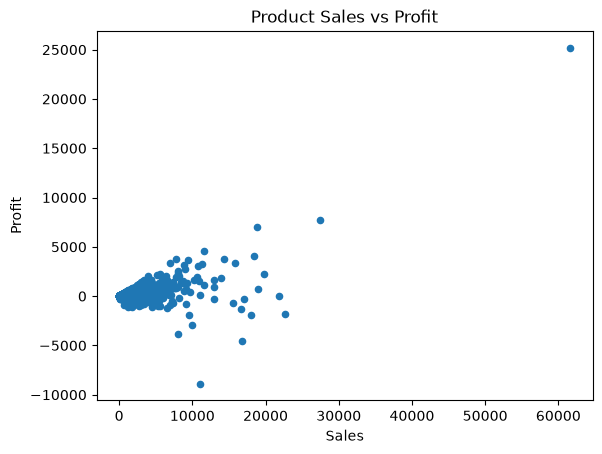

In [60]:
product_summary = df.groupby("Product Name")[["Sales", "Profit"]].sum()
product_summary.plot(kind="scatter", x="Sales", y="Profit", title="Product Sales vs Profit")

**76.** Find products that contribute to the top 20% of total sales.

**77.** Calculate the percentage contribution of each product to overall sales.

**78.** Calculate the percentage contribution of each product to overall profit.

**79.** Rank all products based on sales.

**80.** Rank all products based on profitability.

## Section 5 – Category and Sub-Category Analysis

**81.** Calculate total sales for each product category.

In [61]:
print(df.groupby("Category")["Sales"].sum())

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


**82.** Calculate total profit for each product category.

In [62]:
print(df.groupby("Category")["Profit"].sum())

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


**83.** Calculate total quantity sold for each category.

In [63]:
print(df.groupby("Category")["Quantity"].sum())

Category
Furniture           8028
Office Supplies    22906
Technology          6939
Name: Quantity, dtype: int64


**84.** Calculate average sales for each category.

In [64]:
print(df.groupby("Category")["Sales"].mean())

Category
Furniture          349.834887
Office Supplies    119.324101
Technology         452.709276
Name: Sales, dtype: float64


**85.** Calculate profit margin for each category.

In [65]:
category_data = df.groupby("Category")[["Sales", "Profit"]].sum()
print(category_data["Profit"] / category_data["Sales"] * 100)

Category
Furniture           2.486695
Office Supplies    17.035158
Technology         17.395712
dtype: float64


**86.** Identify the category generating the highest sales.

In [66]:
print(df.groupby("Category")["Sales"].sum().idxmax())

Technology


**87.** Identify the category generating the highest profit.

In [67]:
print(df.groupby("Category")["Profit"].sum().idxmax())

Technology


**88.** Identify the category with the lowest profit margin.

In [68]:
category_data = df.groupby("Category")[["Sales", "Profit"]].sum()
print((category_data["Profit"] / category_data["Sales"] * 100).idxmin())

Furniture


**89.** Calculate sales for each sub-category.

In [69]:
print(df.groupby("Sub-Category")["Sales"].sum())

Sub-Category
Accessories    167380.3180
Appliances     107532.1610
Art             27118.7920
Binders        203412.7330
Bookcases      114879.9963
Chairs         328449.1030
Copiers        149528.0300
Envelopes       16476.4020
Fasteners        3024.2800
Furnishings     91705.1640
Labels          12486.3120
Machines       189238.6310
Paper           78479.2060
Phones         330007.0540
Storage        223843.6080
Supplies        46673.5380
Tables         206965.5320
Name: Sales, dtype: float64


**90.** Calculate profit for each sub-category.

In [70]:
print(df.groupby("Sub-Category")["Profit"].sum())

Sub-Category
Accessories    41936.6357
Appliances     18138.0054
Art             6527.7870
Binders        30221.7633
Bookcases      -3472.5560
Chairs         26590.1663
Copiers        55617.8249
Envelopes       6964.1767
Fasteners        949.5182
Furnishings    13059.1436
Labels          5546.2540
Machines        3384.7569
Paper          34053.5693
Phones         44515.7306
Storage        21278.8264
Supplies       -1189.0995
Tables        -17725.4811
Name: Profit, dtype: float64


**91.** Identify the top five sub-categories by sales.

In [71]:
print(df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).head(5))

Sub-Category
Phones     330007.054
Chairs     328449.103
Storage    223843.608
Tables     206965.532
Binders    203412.733
Name: Sales, dtype: float64


**92.** Identify the top five sub-categories by profit.

In [72]:
print(df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(5))

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Name: Profit, dtype: float64


**93.** Identify the bottom five sub-categories by profit.

In [73]:
print(df.groupby("Sub-Category")["Profit"].sum().sort_values().head(5))

Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


**94.** Identify sub-categories generating negative profits.

In [74]:
sub_profit = df.groupby("Sub-Category")["Profit"].sum()
print(sub_profit[sub_profit < 0])

Sub-Category
Bookcases    -3472.5560
Supplies     -1189.0995
Tables      -17725.4811
Name: Profit, dtype: float64


**95.** Compare Furniture, Office Supplies and Technology in terms of sales and profit.

In [75]:
print(df.groupby("Category")[["Sales", "Profit"]].sum())

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


**96.** Create a category-wise sales and profit comparison chart.

**97.** Create a sub-category-wise profitability chart.

**98.** Identify sub-categories with high sales but negative profit.

**99.** Calculate each sub-category's contribution to its parent category's sales.

**100.** Determine which category should receive more business investment based on sales and profitability.

## Section 6 – Discount Analysis

**101.** Calculate the total number of transactions where a discount was applied.

In [76]:
print("Transactions with discount:", (df["Discount"] > 0).sum())

Transactions with discount: 5196


**102.** Identify all unique discount percentages.

In [77]:
print(df["Discount"].unique())

[0.   0.45 0.2  0.8  0.3  0.5  0.7  0.6  0.32 0.1  0.4  0.15]


**103.** Calculate the average discount offered by the company.

In [78]:
print("Average discount:", df["Discount"].mean())

Average discount: 0.1562027216329798


**104.** Calculate total sales for each discount level.

In [79]:
print(df.groupby("Discount")["Sales"].sum())

Discount
0.00    1.087908e+06
0.10    5.436935e+04
0.15    2.755852e+04
0.20    7.645944e+05
0.30    1.032267e+05
0.32    1.449346e+04
0.40    1.164178e+05
0.45    5.484974e+03
0.50    5.891854e+04
0.60    6.644700e+03
0.70    4.062028e+04
0.80    1.696376e+04
Name: Sales, dtype: float64


**105.** Calculate total profit for each discount level.

In [80]:
print(df.groupby("Discount")["Profit"].sum())

Discount
0.00    320987.6032
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64


**106.** Calculate average profit at each discount level.

In [81]:
print(df.groupby("Discount")["Profit"].mean())

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


**107.** Compare profit margins for discounted and non-discounted transactions.

In [82]:
discounted = df[df["Discount"] > 0]["Profit"].sum() / df[df["Discount"] > 0]["Sales"].sum() * 100
not_discounted = df[df["Discount"] == 0]["Profit"].sum() / df[df["Discount"] == 0]["Sales"].sum() * 100
print("Discounted margin:", discounted)
print("Non-discounted margin:", not_discounted)

Discounted margin: -2.8603985088683803
Non-discounted margin: 29.505019222802808


**108.** Identify transactions where a discount resulted in negative profit.

In [83]:
print(df[(df["Discount"] > 0) & (df["Profit"] < 0)])

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
14        15  US-2015-118983  11/22/2015  11/26/2015  Standard Class   
15        16  US-2015-118983  11/22/2015  11/26/2015  Standard Class   
23        24  US-2017-156909   7/16/2017   7/18/2017    Second Class   
27        28  US-2015-150630   9/17/2015   9/21/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9920    9921  CA-2016-149272   3/15/2016   3/19/2016  Standard Class   
9921    9922  CA-2014-111360  11/24/2014  11/30/2014  Standard Class   
9931    9932  CA-2015-104948  11/13/2015  11/17/2015  Standard Class   
9937    9938  CA-2016-164889    6/3/2016    6/6/2016    Second Class   
9962    9963  CA-2015-168088   3/19/2015   3/22/2015     First Class   

     Customer ID     Customer Name      Segment        Country  \
3       SO-20335    Sean O'Donnell     Consumer  United States   
14 

**109.** Find products where higher discounts are associated with losses.

In [84]:
print(df.groupby("Product Name")[["Discount", "Profit"]].mean().sort_values("Discount", ascending=False).head(10))

                                                    Discount    Profit
Product Name                                                          
Eureka Disposable Bags for Sanitaire Vibra Groo...  0.800000   -4.4660
GBC Plasticlear Binding Covers                      0.728571   -9.7744
GBC VeloBinder Electric Binding Machine             0.725000 -102.8330
Epson Perfection V600 Photo Scanner                 0.700000 -172.4925
Lexmark MarkNet N8150 Wireless Print Server         0.700000 -253.2285
Zebra GK420t Direct Thermal/Thermal Transfer Pr...  0.700000 -938.2800
Hewlett-Packard Deskjet F4180 All-in-One Color ...  0.700000  -71.3958
Bush Westfield Collection Bookcases, Dark Cherr...  0.700000 -190.8522
Cisco 8961 IP Phone Charcoal                        0.700000 -164.9538
Brother MFC-9340CDW LED All-In-One Printer, Cop...  0.700000 -319.1916


**110.** Calculate the relationship between discount and profit.

In [85]:
print("Correlation:", df["Discount"].corr(df["Profit"]))

Correlation: -0.21948745637176806


**111.** Create a scatter plot showing Discount versus Profit.

<Axes: title={'center': 'Discount versus Profit'}, xlabel='Discount', ylabel='Profit'>

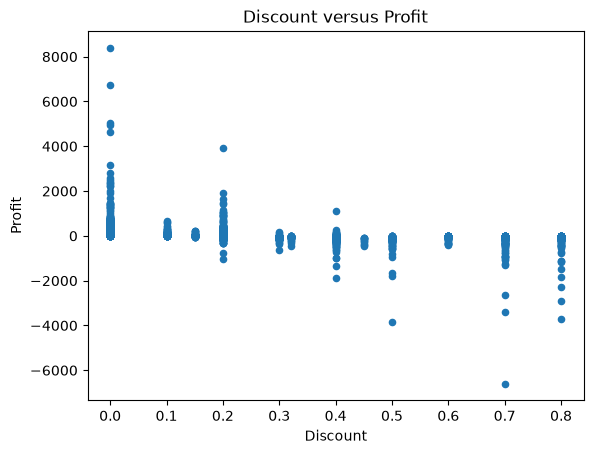

In [86]:
df.plot(kind="scatter", x="Discount", y="Profit", title="Discount versus Profit")

**112.** Identify the discount percentage associated with the highest average profit.

In [87]:
print(df.groupby("Discount")["Profit"].mean().idxmax())

0.1


**113.** Identify categories where discounts have the greatest negative impact on profit.

In [88]:
print(df.groupby("Category")["Profit"].sum().sort_values())

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


**114.** Identify sub-categories where discounts are associated with increased sales but reduced profit.

In [89]:
print(df.groupby("Sub-Category")[["Sales", "Profit"]].sum())

                    Sales      Profit
Sub-Category                         
Accessories   167380.3180  41936.6357
Appliances    107532.1610  18138.0054
Art            27118.7920   6527.7870
Binders       203412.7330  30221.7633
Bookcases     114879.9963  -3472.5560
Chairs        328449.1030  26590.1663
Copiers       149528.0300  55617.8249
Envelopes      16476.4020   6964.1767
Fasteners       3024.2800    949.5182
Furnishings    91705.1640  13059.1436
Labels         12486.3120   5546.2540
Machines      189238.6310   3384.7569
Paper          78479.2060  34053.5693
Phones        330007.0540  44515.7306
Storage       223843.6080  21278.8264
Supplies       46673.5380  -1189.0995
Tables        206965.5320 -17725.4811


**115.** Recommend an appropriate discount strategy based on the findings.

In [90]:
print(df.groupby("Discount")["Profit"].mean().sort_values(ascending=False))

Discount
0.10     96.055074
0.00     66.900292
0.15     27.288298
0.20     24.702572
0.60    -43.077212
0.30    -45.679636
0.32    -88.560656
0.70    -95.874060
0.80   -101.796797
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
Name: Profit, dtype: float64


## Section 7 – Customer Analysis

**116.** Calculate total sales generated by each customer.

In [91]:
print(df.groupby("Customer Name")["Sales"].sum())

Customer Name
Aaron Bergman          886.156
Aaron Hawkins         1744.700
Aaron Smayling        3050.692
Adam Bellavance       7755.620
Adam Hart             3250.337
                        ...   
Xylona Preis          2374.658
Yana Sorensen         6720.444
Yoseph Carroll        5454.350
Zuschuss Carroll      8025.707
Zuschuss Donatelli    1493.944
Name: Sales, Length: 793, dtype: float64


**117.** Calculate total profit generated by each customer.

In [92]:
print(df.groupby("Customer Name")["Profit"].sum())

Customer Name
Aaron Bergman          129.3465
Aaron Hawkins          365.2152
Aaron Smayling        -253.5746
Adam Bellavance       2054.5885
Adam Hart              281.1890
                        ...    
Xylona Preis           621.2300
Yana Sorensen         1778.2923
Yoseph Carroll        1305.6290
Zuschuss Carroll     -1032.1490
Zuschuss Donatelli     249.1307
Name: Profit, Length: 793, dtype: float64


**118.** Calculate the total number of orders placed by each customer.

In [93]:
print(df.groupby("Customer Name")["Order ID"].nunique())

Customer Name
Aaron Bergman          3
Aaron Hawkins          7
Aaron Smayling         7
Adam Bellavance        8
Adam Hart             10
                      ..
Xylona Preis          11
Yana Sorensen          8
Yoseph Carroll         5
Zuschuss Carroll      13
Zuschuss Donatelli     5
Name: Order ID, Length: 793, dtype: int64


**119.** Identify the top 10 customers based on sales.

In [94]:
print(df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10))

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


**120.** Identify the top 10 customers based on profit.

In [95]:
print(df.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False).head(10))

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


**121.** Identify the bottom 10 customers based on profit.

In [96]:
print(df.groupby("Customer Name")["Profit"].sum().sort_values().head(10))

Customer Name
Cindy Stewart      -6626.3895
Grant Thornton     -4108.6589
Luke Foster        -3583.9770
Sharelle Roach     -3333.9144
Henry Goldwyn      -2797.9635
Nathan Cano        -2204.8072
Sean Braxton       -2082.7451
Sean Miller        -1980.7393
Christine Phan     -1850.3029
Natalie Fritzler   -1695.9714
Name: Profit, dtype: float64


**122.** Identify customers who generated losses for the company.

In [97]:
customer_profit = df.groupby("Customer Name")["Profit"].sum()
print(customer_profit[customer_profit < 0])

Customer Name
Aaron Smayling      -253.5746
Adrian Hane           -2.3146
Alan Haines         -378.5509
Alex Avila          -362.8825
Alex Grayson          -5.1371
                      ...    
Victoria Pisteka   -1018.7768
Victoria Wilson     -874.6645
Vivek Grady          -52.3330
Vivek Sundaresam    -262.8093
Zuschuss Carroll   -1032.1490
Name: Profit, Length: 155, dtype: float64


**123.** Calculate average order value for each customer.

In [98]:
customer_sales = df.groupby("Customer Name")["Sales"].sum()
customer_orders = df.groupby("Customer Name")["Order ID"].nunique()
print(customer_sales / customer_orders)

Customer Name
Aaron Bergman          295.385333
Aaron Hawkins          249.242857
Aaron Smayling         435.813143
Adam Bellavance        969.452500
Adam Hart              325.033700
                         ...     
Xylona Preis           215.878000
Yana Sorensen          840.055500
Yoseph Carroll        1090.870000
Zuschuss Carroll       617.362077
Zuschuss Donatelli     298.788800
Length: 793, dtype: float64


**124.** Identify customers with the highest average order value.

In [99]:
customer_sales = df.groupby("Customer Name")["Sales"].sum()
customer_orders = df.groupby("Customer Name")["Order ID"].nunique()
print((customer_sales / customer_orders).sort_values(ascending=False).head(10))

Customer Name
Sean Miller             5008.610000
Tamara Chand            3810.443600
Tom Ashbrook            3648.905000
Grant Thornton          3117.070667
Becky Martin            2947.407500
Mitch Willingham        2626.938000
Raymond Buch            2519.556500
Christopher Conant      2425.814400
Peter Fuller            2265.716000
Christopher Martinez    2238.505000
dtype: float64


**125.** Calculate the number of unique products purchased by each customer.

In [100]:
print(df.groupby("Customer Name")["Product ID"].nunique())

Customer Name
Aaron Bergman          6
Aaron Hawkins         11
Aaron Smayling        10
Adam Bellavance       17
Adam Hart             20
                      ..
Xylona Preis          28
Yana Sorensen         11
Yoseph Carroll         8
Zuschuss Carroll      31
Zuschuss Donatelli     9
Name: Product ID, Length: 793, dtype: int64


**126.** Identify customers purchasing products from multiple categories.

In [101]:
customer_categories = df.groupby("Customer Name")["Category"].nunique()
print(customer_categories[customer_categories > 1])

Customer Name
Aaron Bergman         3
Aaron Hawkins         3
Aaron Smayling        3
Adam Bellavance       3
Adam Hart             3
                     ..
Xylona Preis          3
Yana Sorensen         3
Yoseph Carroll        3
Zuschuss Carroll      3
Zuschuss Donatelli    3
Name: Category, Length: 772, dtype: int64


**127.** Calculate sales by customer segment.

In [102]:
print(df.groupby("Segment")["Sales"].sum())

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


**128.** Calculate profit by customer segment.

In [103]:
print(df.groupby("Segment")["Profit"].sum())

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


**129.** Compare Consumer, Corporate and Home Office segments.

In [104]:
print(df.groupby("Segment")[["Sales", "Profit"]].sum())

                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


**130.** Identify which customer segment has the highest average order value.

In [105]:
customer_segment = df.groupby("Segment").agg({"Sales": "sum", "Order ID": "nunique"})
print(customer_segment["Sales"] / customer_segment["Order ID"])

Segment
Consumer       449.111116
Corporate      466.411075
Home Office    472.665730
dtype: float64


**131.** Identify the most profitable customer segment.

**132.** Calculate each customer's contribution to overall sales.

**133.** Rank customers based on their total sales.

**134.** Perform customer segmentation using sales and profit.

**135.** Identify customers who generate high sales but low profits.

## Section 8 – Regional and Geographical Analysis

**136.** Calculate total sales for each region.

In [106]:
print(df.groupby("Region")["Sales"].sum())

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


**137.** Calculate total profit for each region.

In [107]:
print(df.groupby("Region")["Profit"].sum())

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


**138.** Calculate profit margin for each region.

In [108]:
region_data = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_data["Profit"] / region_data["Sales"] * 100)

Region
Central     7.921629
East       13.483399
South      11.934342
West       14.944831
dtype: float64


**139.** Identify the region with the highest sales.

In [109]:
print(df.groupby("Region")["Sales"].sum().idxmax())

West


**140.** Identify the region with the highest profit.

In [110]:
print(df.groupby("Region")["Profit"].sum().idxmax())

West


**141.** Identify regions generating negative profits.

In [111]:
region_profit = df.groupby("Region")["Profit"].sum()
print(region_profit[region_profit < 0])

Series([], Name: Profit, dtype: float64)


**142.** Calculate sales by state and region.

In [112]:
print(df.groupby(["State", "Region"])["Sales"].sum())

State                 Region 
Alabama               South       19510.6400
Arizona               West        35282.0010
Arkansas              South       11678.1300
California            West       457687.6315
Colorado              West        32108.1180
Connecticut           East        13384.3570
Delaware              East        27451.0690
District of Columbia  East         2865.0200
Florida               South       89473.7080
Georgia               South       49095.8400
Idaho                 West         4382.4860
Illinois              Central     80166.1010
Indiana               Central     53555.3600
Iowa                  Central      4579.7600
Kansas                Central      2914.3100
Kentucky              South       36591.7500
Louisiana             South        9217.0300
Maine                 East         1270.5300
Maryland              East        23705.5230
Massachusetts         East        28634.4340
Michigan              Central     76269.6140
Minnesota             Cen

**143.** Identify the top five cities in each region based on sales.

In [113]:
city_region = df.groupby(["Region", "City"])["Sales"].sum().reset_index()
print(city_region.sort_values(["Region", "Sales"], ascending=[True, False]).groupby("Region").head(5))

      Region           City        Sales
75   Central        Houston   64504.7604
27   Central        Chicago   48539.5410
44   Central        Detroit   42446.9440
154  Central    San Antonio   21843.5280
36   Central         Dallas   20131.9322
254     East  New York City  256368.1610
264     East   Philadelphia  109077.0130
255     East         Newark   28576.1190
227     East       Lakewood   16608.3640
266     East     Providence   15980.6500
345    South   Jacksonville   44713.1830
294    South        Atlanta   17197.8400
398    South    Springfield   16628.5300
335    South      Henderson   15661.0100
311    South       Columbus   14845.0500
494     West    Los Angeles  175851.3410
558     West        Seattle  119540.7420
547     West  San Francisco  112669.0920
546     West      San Diego   47521.0290
449     West         Denver   12198.7930


**144.** Identify the top five cities in each region based on profit.

In [114]:
city_region = df.groupby(["Region", "City"])["Profit"].sum().reset_index()
print(city_region.sort_values(["Region", "Profit"], ascending=[True, False]).groupby("Region").head(5))

      Region             City      Profit
44   Central          Detroit  13181.7908
88   Central        Lafayette   8976.0973
106  Central      Minneapolis   6824.5846
81   Central          Jackson   5525.1992
160  Central      Springfield   3905.5891
254     East    New York City  62036.9837
255     East           Newark   5793.7588
266     East       Providence   5505.6569
204     East         Columbia   3775.2237
227     East         Lakewood   3190.0654
294    South          Atlanta   6993.6629
398    South      Springfield   4568.5789
335    South        Henderson   4518.8169
291    South        Arlington   4424.0855
311    South         Columbus   4104.1219
494     West      Los Angeles  30440.7579
558     West          Seattle  29156.0967
547     West    San Francisco  17507.3854
546     West        San Diego   6377.1960
510     West  North Las Vegas   2247.6899


**145.** Compare sales performance across states.

In [115]:
print(df.groupby("State")["Sales"].sum().sort_values(ascending=False))

State
California              457687.6315
New York                310876.2710
Texas                   170188.0458
Washington              138641.2700
Pennsylvania            116511.9140
Florida                  89473.7080
Illinois                 80166.1010
Ohio                     78258.1360
Michigan                 76269.6140
Virginia                 70636.7200
North Carolina           55603.1640
Indiana                  53555.3600
Georgia                  49095.8400
Kentucky                 36591.7500
New Jersey               35764.3120
Arizona                  35282.0010
Wisconsin                32114.6100
Colorado                 32108.1180
Tennessee                30661.8730
Minnesota                29863.1500
Massachusetts            28634.4340
Delaware                 27451.0690
Maryland                 23705.5230
Rhode Island             22627.9560
Missouri                 22205.1500
Oklahoma                 19683.3900
Alabama                  19510.6400
Oregon                

**146.** Identify states with high sales but low profit.

In [116]:
state_data = df.groupby("State")[["Sales", "Profit"]].sum()
print(state_data[(state_data["Sales"] > state_data["Sales"].median()) & (state_data["Profit"] < state_data["Profit"].median())])

                      Sales      Profit
State                                  
Arizona          35282.0010  -3427.9246
Colorado         32108.1180  -6527.8579
Florida          89473.7080  -3399.3017
Illinois         80166.1010 -12607.8870
North Carolina   55603.1640  -7490.9122
Ohio             78258.1360 -16971.3766
Pennsylvania    116511.9140 -15559.9603
Tennessee        30661.8730  -5341.6936
Texas           170188.0458 -25729.3563


**147.** Identify states with low sales but high profit.

In [117]:
state_data = df.groupby("State")[["Sales", "Profit"]].sum()
print(state_data[(state_data["Sales"] < state_data["Sales"].median()) & (state_data["Profit"] > state_data["Profit"].median())])

                 Sales     Profit
State                            
Alabama      19510.640  5786.8253
Arkansas     11678.130  4008.6871
Connecticut  13384.357  3511.4918
Mississippi  10771.340  3172.9762
Nevada       16729.102  3316.7659
Oklahoma     19683.390  4853.9560
Utah         11220.056  2546.5335
Vermont       8929.370  2244.9783


**148.** Calculate the number of unique customers in each region.

In [118]:
print(df.groupby("Region")["Customer ID"].nunique())

Region
Central    629
East       674
South      512
West       686
Name: Customer ID, dtype: int64


**149.** Calculate average sales per customer in each region.

In [119]:
region_sales = df.groupby("Region")["Sales"].sum()
region_customers = df.groupby("Region")["Customer ID"].nunique()
print(region_sales / region_customers)

Region
Central     796.883769
East       1007.093828
South       765.081846
West       1057.518695
dtype: float64


**150.** Determine which region should receive additional marketing investment.

In [120]:
region_data = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_data.sort_values("Profit", ascending=False))

               Sales       Profit
Region                           
West     725457.8245  108418.4489
East     678781.2400   91522.7800
South    391721.9050   46749.4303
Central  501239.8908   39706.3625


## Section 9 – Time-Series Analysis

**151.** Convert Order Date into a proper datetime format.

In [121]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df["Order Date"].head())

0   2016-11-08
1   2016-11-08
2   2016-06-12
3   2015-10-11
4   2015-10-11
Name: Order Date, dtype: datetime64[us]


**152.** Extract the year from Order Date.

In [122]:
df["Year"] = df["Order Date"].dt.year
print(df[["Order Date", "Year"]].head())

  Order Date  Year
0 2016-11-08  2016
1 2016-11-08  2016
2 2016-06-12  2016
3 2015-10-11  2015
4 2015-10-11  2015


**153.** Extract the month from Order Date.

In [123]:
df["Month"] = df["Order Date"].dt.month
print(df[["Order Date", "Month"]].head())

  Order Date  Month
0 2016-11-08     11
1 2016-11-08     11
2 2016-06-12      6
3 2015-10-11     10
4 2015-10-11     10


**154.** Extract the month name from Order Date.

In [124]:
df["Month Name"] = df["Order Date"].dt.month_name()
print(df[["Order Date", "Month Name"]].head())

  Order Date Month Name
0 2016-11-08   November
1 2016-11-08   November
2 2016-06-12       June
3 2015-10-11    October
4 2015-10-11    October


**155.** Extract the quarter from Order Date.

In [125]:
df["Quarter"] = df["Order Date"].dt.quarter
print(df[["Order Date", "Quarter"]].head())

  Order Date  Quarter
0 2016-11-08        4
1 2016-11-08        4
2 2016-06-12        2
3 2015-10-11        4
4 2015-10-11        4


**156.** Calculate total sales for each year.

In [126]:
print(df.groupby("Year")["Sales"].sum())

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


**157.** Calculate total profit for each year.

In [127]:
print(df.groupby("Year")["Profit"].sum())

Year
2014    49543.9741
2015    61618.6037
2016    81795.1743
2017    93439.2696
Name: Profit, dtype: float64


**158.** Calculate monthly sales for the entire dataset.

In [128]:
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
print(monthly_sales)

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


**159.** Calculate monthly profit for the entire dataset.

In [129]:
monthly_profit = df.groupby(df["Order Date"].dt.to_period("M"))["Profit"].sum()
print(monthly_profit)

Order Date
2014-01     2450.1907
2014-02      862.3084
2014-03      498.7299
2014-04     3488.8352
2014-05     2738.7096
2014-06     4976.5244
2014-07     -841.4826
2014-08     5318.1050
2014-09     8328.0994
2014-10     3448.2573
2014-11     9292.1269
2014-12     8983.5699
2015-01    -3281.0070
2015-02     2813.8508
2015-03     9732.0978
2015-04     4187.4962
2015-05     4667.8690
2015-06     3335.5572
2015-07     3288.6483
2015-08     5355.8084
2015-09     8209.1627
2015-10     2817.3660
2015-11    12474.7884
2015-12     8016.9659
2016-01     2824.8233
2016-02     5004.5795
2016-03     3611.9680
2016-04     2977.8149
2016-05     8662.1464
2016-06     4750.3781
2016-07     4432.8779
2016-08     2062.0693
2016-09     9328.6576
2016-10    16243.1425
2016-11     4011.4075
2016-12    17885.3093
2017-01     7140.4391
2017-02     1613.8720
2017-03    14751.8915
2017-04      933.2900
2017-05     6342.5828
2017-06     8223.3357
2017-07     6952.6212
2017-08     9040.9557
2017-09    10991.5556

**160.** Identify the month with the highest sales.

In [130]:
monthly_sales = df.groupby(df["Order Date"].dt.month_name())["Sales"].sum()
print(monthly_sales.idxmax())

November


**161.** Identify the month with the lowest sales.

In [131]:
monthly_sales = df.groupby(df["Order Date"].dt.month_name())["Sales"].sum()
print(monthly_sales.idxmin())

February


**162.** Identify the month with the highest profit.

In [132]:
monthly_profit = df.groupby(df["Order Date"].dt.month_name())["Profit"].sum()
print(monthly_profit.idxmax())

December


**163.** Compare annual sales performance.

In [133]:
print(df.groupby("Year")["Sales"].sum())

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


**164.** Calculate year-over-year sales growth.

In [134]:
year_sales = df.groupby("Year")["Sales"].sum()
print(year_sales.pct_change() * 100)

Year
2014          NaN
2015    -2.832227
2016    29.471521
2017    20.355962
Name: Sales, dtype: float64


**165.** Calculate year-over-year profit growth.

In [135]:
year_profit = df.groupby("Year")["Profit"].sum()
print(year_profit.pct_change() * 100)

Year
2014          NaN
2015    24.371540
2016    32.744284
2017    14.235675
Name: Profit, dtype: float64


**166.** Calculate quarterly sales for each year.

**167.** Identify seasonal sales patterns.

**168.** Compare sales performance across different quarters.

**169.** Calculate a three-month moving average of sales.

**170.** Calculate a three-month moving average of profit.

**171.** Plot monthly sales trends using a line chart.

**172.** Plot monthly profit trends using a line chart.

**173.** Determine whether sales are increasing or decreasing over time.

**174.** Identify months where sales increased but profit decreased.

**175.** Recommend business strategies based on seasonal trends.

## Section 10 – Order and Shipping Analysis

**176.** Calculate the total number of unique orders.

In [136]:
print("Unique orders:", df["Order ID"].nunique())

Unique orders: 5009


**177.** Calculate the average number of products per order.

In [137]:
order_rows = df.groupby("Order ID").size()
print(order_rows.mean())

1.9952086244759433


**178.** Identify the largest order based on total sales.

In [138]:
order_sales = df.groupby("Order ID")["Sales"].sum()
print(order_sales.idxmax())
print(order_sales.max())

CA-2014-145317
23661.228


**179.** Identify the smallest order based on total sales.

In [139]:
order_sales = df.groupby("Order ID")["Sales"].sum()
print(order_sales.idxmin())
print(order_sales.min())

CA-2017-124114
0.556


**180.** Calculate total sales per order.

In [140]:
print(df.groupby("Order ID")["Sales"].sum())

Order ID
CA-2014-100006     377.970
CA-2014-100090     699.192
CA-2014-100293      91.056
CA-2014-100328       3.928
CA-2014-100363      21.376
                    ...   
US-2017-168802      18.368
US-2017-169320     171.430
US-2017-169488      56.860
US-2017-169502     113.410
US-2017-169551    1344.838
Name: Sales, Length: 5009, dtype: float64


**181.** Calculate total profit per order.

In [141]:
print(df.groupby("Order ID")["Profit"].sum())

Order ID
CA-2014-100006    109.6113
CA-2014-100090    -19.0890
CA-2014-100293     31.8696
CA-2014-100328      1.3257
CA-2014-100363      7.7192
                    ...   
US-2017-168802      5.9696
US-2017-169320     16.6721
US-2017-169488     26.5552
US-2017-169502     32.4527
US-2017-169551    -62.2895
Name: Profit, Length: 5009, dtype: float64


**182.** Identify orders containing multiple product categories.

In [142]:
order_categories = df.groupby("Order ID")["Category"].nunique()
print(order_categories[order_categories > 1])

Order ID
CA-2014-100090    2
CA-2014-100678    3
CA-2014-100706    2
CA-2014-100895    2
CA-2014-100916    2
                 ..
US-2017-167402    2
US-2017-167920    2
US-2017-168116    2
US-2017-169320    2
US-2017-169551    3
Name: Category, Length: 1717, dtype: int64


**183.** Identify the most frequently used shipping mode.

In [143]:
print(df["Ship Mode"].value_counts().idxmax())

Standard Class


**184.** Calculate total sales by shipping mode.

In [144]:
print(df.groupby("Ship Mode")["Sales"].sum())

Ship Mode
First Class       3.514284e+05
Same Day          1.283631e+05
Second Class      4.591936e+05
Standard Class    1.358216e+06
Name: Sales, dtype: float64


**185.** Calculate total profit by shipping mode.

In [145]:
print(df.groupby("Ship Mode")["Profit"].sum())

Ship Mode
First Class        48969.8399
Same Day           15891.7589
Second Class       57446.6354
Standard Class    164088.7875
Name: Profit, dtype: float64


**186.** Calculate the average shipping duration using Ship Date and Order Date.

In [146]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(df["Shipping Days"].mean())

3.958174904942966


**187.** Identify orders with the longest shipping duration.

In [147]:
order_days = df.groupby("Order ID")["Shipping Days"].mean()
print(order_days.sort_values(ascending=False).head(10))

Order ID
CA-2016-118332    7.0
CA-2017-128734    7.0
CA-2014-103807    7.0
CA-2017-126956    7.0
CA-2014-100363    7.0
CA-2014-104976    7.0
CA-2014-105270    7.0
CA-2017-164826    7.0
CA-2016-122133    7.0
US-2017-152842    7.0
Name: Shipping Days, dtype: float64


**188.** Identify orders with the shortest shipping duration.

In [148]:
order_days = df.groupby("Order ID")["Shipping Days"].mean()
print(order_days.sort_values().head(10))

Order ID
CA-2015-124891    0.0
CA-2015-129392    0.0
CA-2015-129217    0.0
CA-2015-131072    0.0
CA-2015-130848    0.0
US-2017-131583    0.0
US-2017-135013    0.0
US-2017-142188    0.0
US-2017-168116    0.0
CA-2015-125416    0.0
Name: Shipping Days, dtype: float64


**189.** Compare shipping duration across different shipping modes.

In [149]:
print(df.groupby("Ship Mode")["Shipping Days"].mean())

Ship Mode
First Class       2.182705
Same Day          0.044199
Second Class      3.238046
Standard Class    5.006535
Name: Shipping Days, dtype: float64


**190.** Determine whether shipping mode has any relationship with order profitability.

In [150]:
print(df.groupby("Ship Mode")["Profit"].mean())

Ship Mode
First Class       31.839948
Same Day          29.266591
Second Class      29.535545
Standard Class    27.494770
Name: Profit, dtype: float64


## Section 11 – Advanced Pandas Operations

**191.** Use groupby() to calculate sales by category.

In [151]:
print(df.groupby("Category")["Sales"].sum())

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


**192.** Use groupby() to calculate profit by region.

In [152]:
print(df.groupby("Region")["Profit"].sum())

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


**193.** Use multiple columns in groupby() to calculate sales by Region and Category.

In [153]:
print(df.groupby(["Region", "Category"])["Sales"].sum())

Region   Category       
Central  Furniture          163797.1638
         Office Supplies    167026.4150
         Technology         170416.3120
East     Furniture          208291.2040
         Office Supplies    205516.0550
         Technology         264973.9810
South    Furniture          117298.6840
         Office Supplies    125651.3130
         Technology         148771.9080
West     Furniture          252612.7435
         Office Supplies    220853.2490
         Technology         251991.8320
Name: Sales, dtype: float64


**194.** Use pivot_table() to create a Region versus Category sales summary.

In [154]:
print(pd.pivot_table(df, values="Sales", index="Region", columns="Category", aggfunc="sum"))

Category    Furniture  Office Supplies  Technology
Region                                            
Central   163797.1638       167026.415  170416.312
East      208291.2040       205516.055  264973.981
South     117298.6840       125651.313  148771.908
West      252612.7435       220853.249  251991.832


**195.** Create a pivot table showing profit by Segment and Category.

In [155]:
print(pd.pivot_table(df, values="Profit", index="Segment", columns="Category", aggfunc="sum"))

Category     Furniture  Office Supplies  Technology
Segment                                            
Consumer     6991.0786       56330.3210  70797.8096
Corporate    7584.8158       40227.3202  44166.9980
Home Office  3875.3784       25933.1596  30490.1405


**196.** Use crosstab() to count orders by Segment and Ship Mode.

In [156]:
print(pd.crosstab(df["Segment"], df["Ship Mode"]))

Ship Mode    First Class  Same Day  Second Class  Standard Class
Segment                                                         
Consumer             769       317          1020            3085
Corporate            485       114           609            1812
Home Office          284       112           316            1071


**197.** Use sort_values() to identify the top 20 products by sales.

In [157]:
print(df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(20))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.8240
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.3840
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.4800
HON 5400 Series Task Chairs for Big and Tall                                   21870.5760
GBC DocuBind TL300 Electric Binding System                                     19823.4790
GBC Ibimaster 500 Manual ProClick Binding System                               19024.5000
Hewlett Packard LaserJet 3310 Copier                                           18839.6860
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.8950
GBC DocuBind P400 Electric Binding System                                      17965.0680
High Speed Automatic Electric Letter Opener                                    17030.3120
Lexmark MX611dhe Monochrome Laser Printer                                      16829.90

**198.** Use nlargest() to find the top 10 customers by profit.

In [158]:
print(df.groupby("Customer Name")["Profit"].sum().nlargest(10))

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


**199.** Use nsmallest() to find the 10 least profitable products.

In [159]:
print(df.groupby("Product Name")["Profit"].sum().nsmallest(10))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


**200.** Use apply() to calculate a custom profit classification.

In [160]:
df["Profit Class"] = df["Profit"].apply(lambda x: "Profit" if x > 0 else "Loss" if x < 0 else "No Profit")
print(df[["Profit", "Profit Class"]].head())

     Profit Profit Class
0   41.9136       Profit
1  219.5820       Profit
2    6.8714       Profit
3 -383.0310         Loss
4    2.5164       Profit


**201.** Use map() to convert numeric discount values into discount categories.

In [161]:
df["Discount Category"] = df["Discount"].map({0.0: "No Discount", 0.2: "20%", 0.3: "30%", 0.4: "40%", 0.5: "50%", 0.6: "60%", 0.7: "70%", 0.8: "80%"})
print(df["Discount Category"].value_counts())

Discount Category
No Discount    4798
20%            3657
70%             418
80%             300
30%             227
40%             206
60%             138
50%              66
Name: count, dtype: int64


**202.** Use cut() to divide sales into Low, Medium and High sales groups.

In [162]:
df["Sales Group"] = pd.cut(df["Sales"], bins=3, labels=["Low", "Medium", "High"])
print(df["Sales Group"].value_counts())

Sales Group
Low       9981
Medium      11
High         2
Name: count, dtype: int64


**203.** Use qcut() to divide customers into four groups based on sales.

In [163]:
customer_sales = df.groupby("Customer Name")["Sales"].sum().reset_index()
customer_sales["Sales Group"] = pd.qcut(customer_sales["Sales"], 4, labels=["Low", "Medium", "High", "Very High"])
print(customer_sales.head())

     Customer Name     Sales Sales Group
0    Aaron Bergman   886.156         Low
1    Aaron Hawkins  1744.700      Medium
2   Aaron Smayling  3050.692        High
3  Adam Bellavance  7755.620   Very High
4        Adam Hart  3250.337        High


**204.** Use transform() to calculate each product's percentage contribution to its category's sales.

In [164]:
df["Category Sales"] = df.groupby("Category")["Sales"].transform("sum")
df["Product Share"] = df["Sales"] / df["Category Sales"] * 100
print(df[["Product Name", "Category", "Product Share"]].head())

                                        Product Name         Category  \
0                  Bush Somerset Collection Bookcase        Furniture   
1  Hon Deluxe Fabric Upholstered Stacking Chairs,...        Furniture   
2  Self-Adhesive Address Labels for Typewriters b...  Office Supplies   
3      Bretford CR4500 Series Slim Rectangular Table        Furniture   
4                     Eldon Fold 'N Roll Cart System  Office Supplies   

   Product Share  
0       0.035305  
1       0.098644  
2       0.002033  
3       0.129054  
4       0.003111  


**205.** Use rank() to rank products within each category.

In [165]:
product_category = df.groupby(["Category", "Product Name"])["Sales"].sum().reset_index()
product_category["Rank"] = product_category.groupby("Category")["Sales"].rank(ascending=False)
print(product_category.sort_values(["Category", "Rank"]).head(20))

      Category                                       Product Name       Sales  \
206  Furniture       HON 5400 Series Task Chairs for Big and Tall  21870.5760   
321  Furniture  Riverside Palais Royal Lawyers Bookcase, Royal...  15610.9656   
40   Furniture         Bretford Rectangular Conference Table Tops  12995.2915   
201  Furniture      Global Troy Executive Leather Low-Back Tilter  12975.3820   
325  Furniture                           SAFCO Arco Folding Chair  11572.7800   
89   Furniture              DMI Eclipse Executive Suite Bookcases  11046.6090   
225  Furniture  Hon Deluxe Fabric Upholstered Stacking Chairs,...  10637.5280   
63   Furniture  Chromcraft Bull-Nose Wood Oval Conference Tabl...   9917.6400   
42   Furniture  Bush Advantage Collection Racetrack Conference...   9544.7250   
205  Furniture         GuestStacker Chair with Chrome Finish Legs   9070.9440   
313  Furniture  Office Star - Professional Matrix Back Chair w...   8774.5000   
175  Furniture            Gl

**206.** Use merge() to combine separate customer and sales summary DataFrames.

**207.** Use melt() to convert a wide-format sales summary into long format.

**208.** Use filter() to select products with sales greater than a specified threshold.

**209.** Use query() to identify transactions where Profit is negative and Discount is greater than 0.2.

**210.** Use resample() to calculate monthly sales after setting Order Date as the index.

## Section 12 – Data Visualization

**211.** Create a bar chart showing total sales by category.

<Axes: title={'center': 'Sales by Category'}, xlabel='Category', ylabel='Sales'>

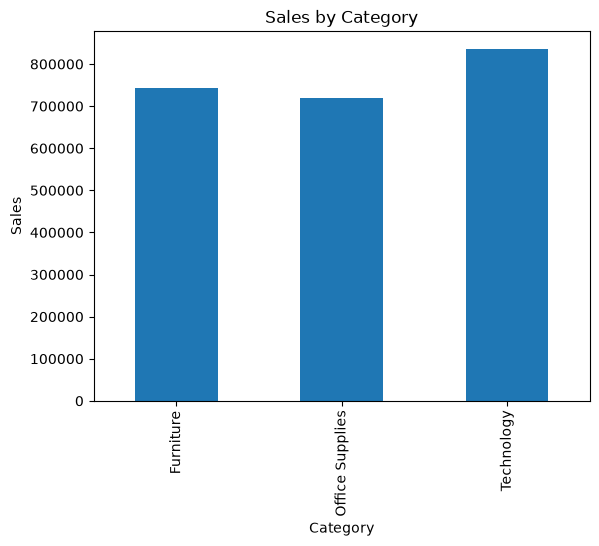

In [166]:
category_sales = df.groupby("Category")["Sales"].sum()
category_sales.plot(kind="bar", title="Sales by Category", ylabel="Sales")

**212.** Create a bar chart showing total profit by category.

<Axes: title={'center': 'Profit by Category'}, xlabel='Category', ylabel='Profit'>

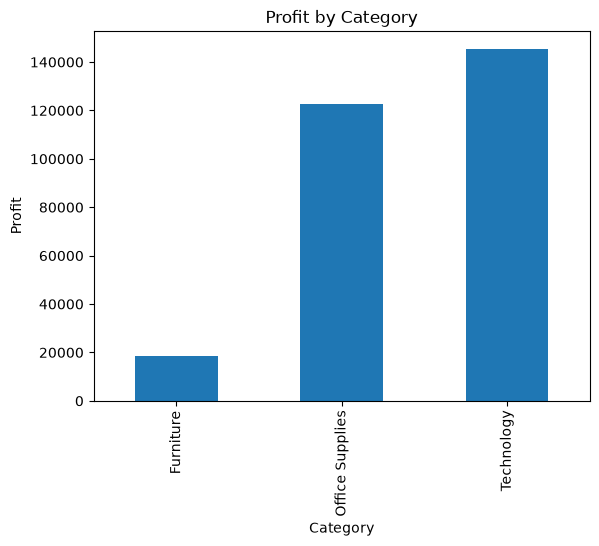

In [167]:
category_profit = df.groupby("Category")["Profit"].sum()
category_profit.plot(kind="bar", title="Profit by Category", ylabel="Profit")

**213.** Create a pie chart showing category-wise sales contribution.

<Axes: title={'center': 'Category-wise Sales'}>

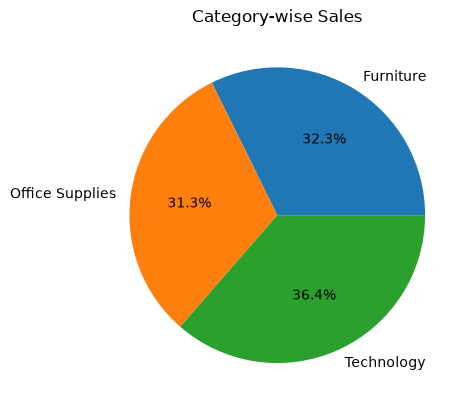

In [168]:
df.groupby("Category")["Sales"].sum().plot(kind="pie", autopct="%1.1f%%", title="Category-wise Sales")

**214.** Create a horizontal bar chart showing the top 10 products by sales.

<Axes: title={'center': 'Top 10 Products by Sales'}, ylabel='Product Name'>

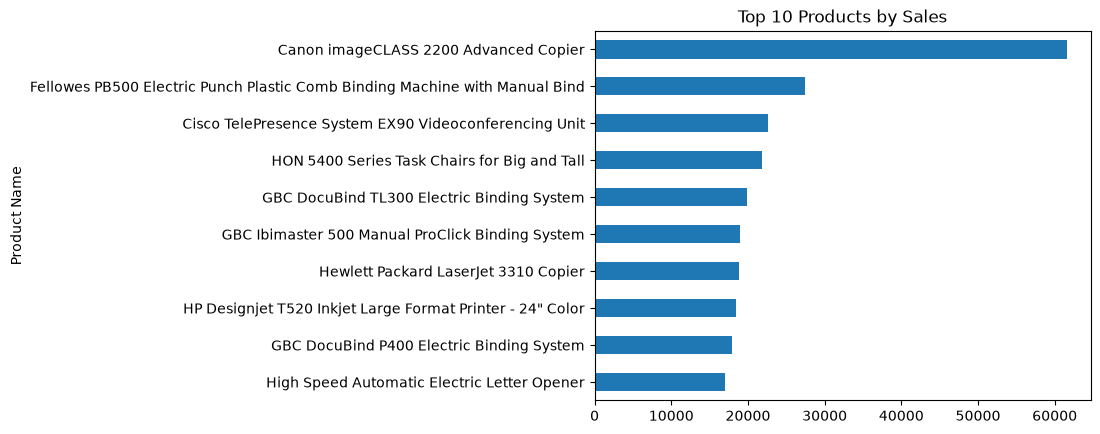

In [169]:
df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values().plot(kind="barh", title="Top 10 Products by Sales")

**215.** Create a horizontal bar chart showing the top 10 products by profit.

<Axes: title={'center': 'Top 10 Products by Profit'}, ylabel='Product Name'>

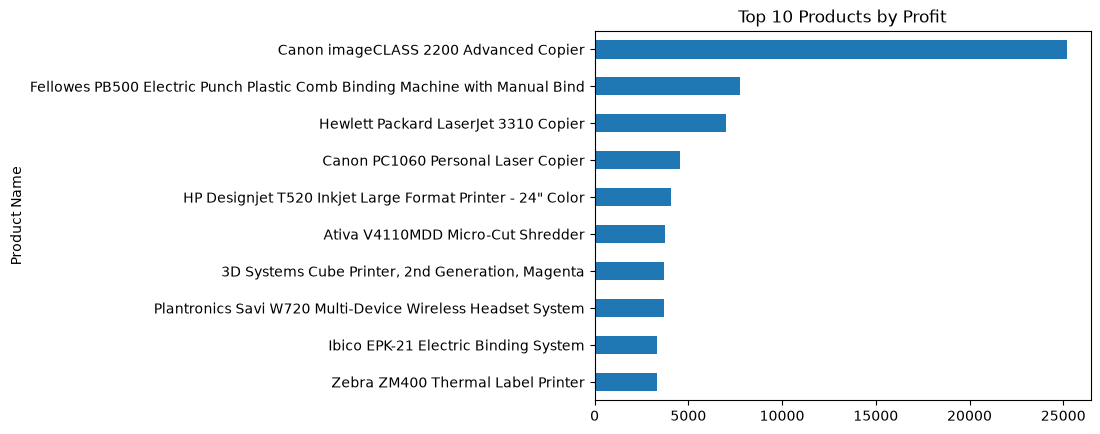

In [170]:
df.groupby("Product Name")["Profit"].sum().nlargest(10).sort_values().plot(kind="barh", title="Top 10 Products by Profit")

**216.** Create a bar chart comparing sales and profit across regions.

<Axes: title={'center': 'Sales and Profit by Region'}, xlabel='Region'>

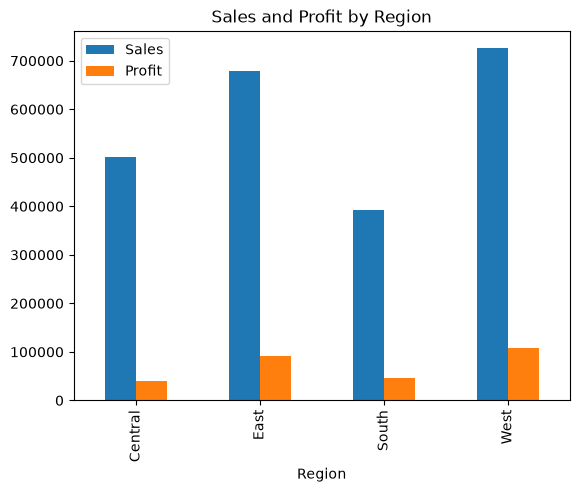

In [171]:
df.groupby("Region")[["Sales", "Profit"]].sum().plot(kind="bar", title="Sales and Profit by Region")

**217.** Create a line chart showing yearly sales trends.

<Axes: title={'center': 'Yearly Sales Trend'}, xlabel='Order Date'>

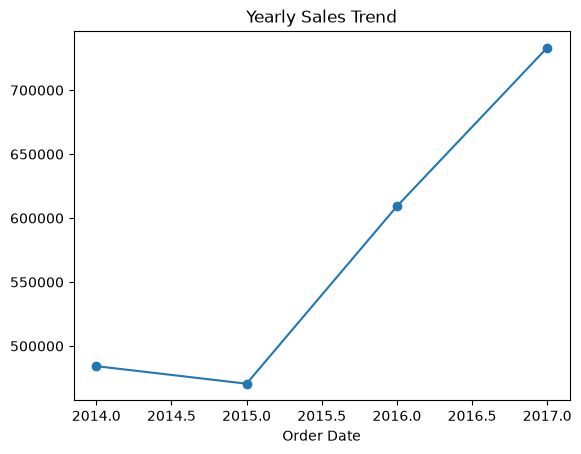

In [172]:
df.groupby(pd.to_datetime(df["Order Date"]).dt.year)["Sales"].sum().plot(kind="line", marker="o", title="Yearly Sales Trend")

**218.** Create a line chart showing monthly sales trends.

<Axes: title={'center': 'Monthly Sales Trend'}, xlabel='Order Date'>

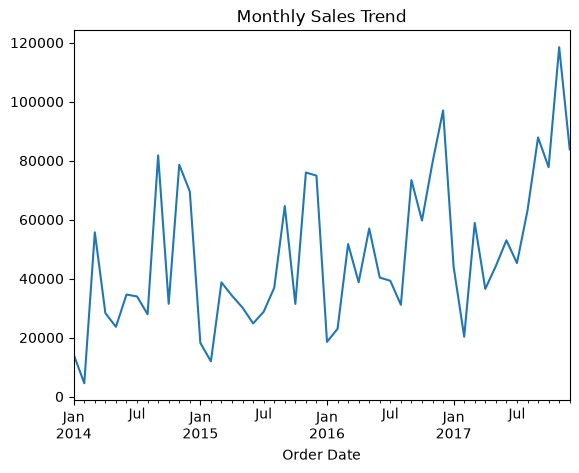

In [173]:
df.groupby(pd.to_datetime(df["Order Date"]).dt.to_period("M"))["Sales"].sum().plot(kind="line", title="Monthly Sales Trend")

**219.** Create a heatmap showing sales by Region and Category.

<Axes: xlabel='Category', ylabel='Region'>

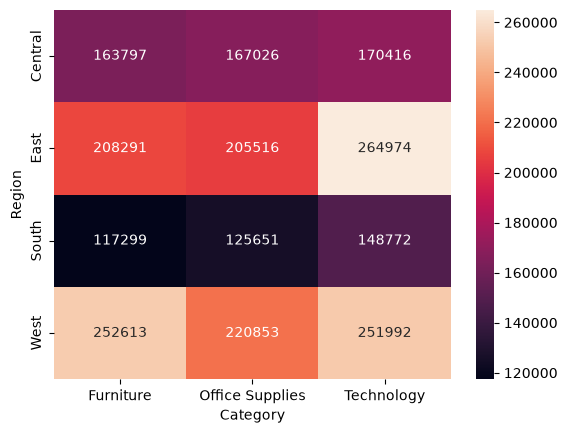

In [174]:
import seaborn as sns
sales_table = pd.pivot_table(df, values="Sales", index="Region", columns="Category", aggfunc="sum")
sns.heatmap(sales_table, annot=True, fmt=".0f")

**220.** Create a heatmap showing profit by Sub-Category and Region.

<Axes: xlabel='Region', ylabel='Sub-Category'>

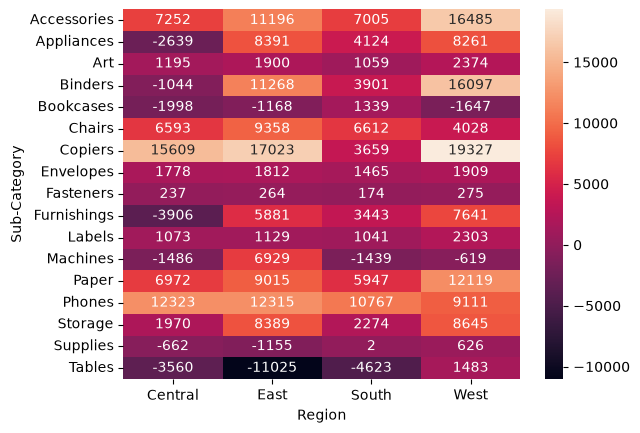

In [175]:
import seaborn as sns
profit_table = pd.pivot_table(df, values="Profit", index="Sub-Category", columns="Region", aggfunc="sum")
sns.heatmap(profit_table, annot=True, fmt=".0f")

**221.** Create a scatter plot showing Sales versus Profit.

<Axes: title={'center': 'Sales versus Profit'}, xlabel='Sales', ylabel='Profit'>

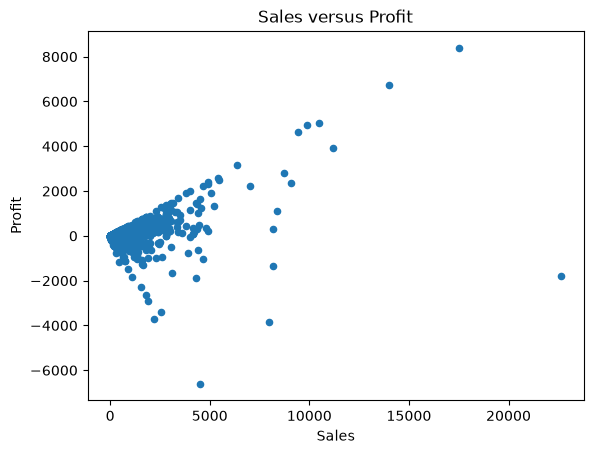

In [176]:
df.plot(kind="scatter", x="Sales", y="Profit", title="Sales versus Profit")

**222.** Create a scatter plot showing Discount versus Profit.

<Axes: title={'center': 'Discount versus Profit'}, xlabel='Discount', ylabel='Profit'>

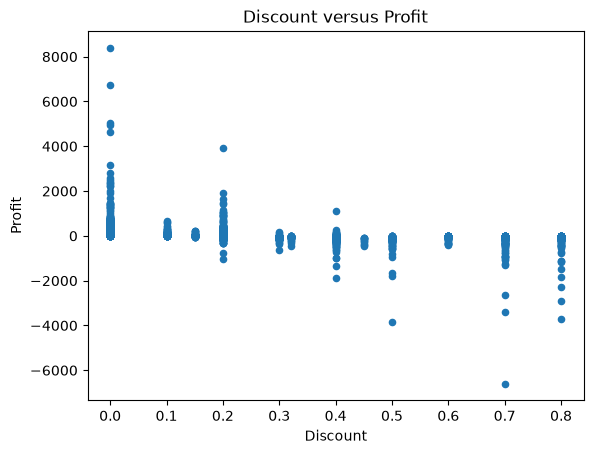

In [177]:
df.plot(kind="scatter", x="Discount", y="Profit", title="Discount versus Profit")

**223.** Create a histogram showing the distribution of Sales.

<Axes: title={'center': 'Sales Distribution'}, ylabel='Frequency'>

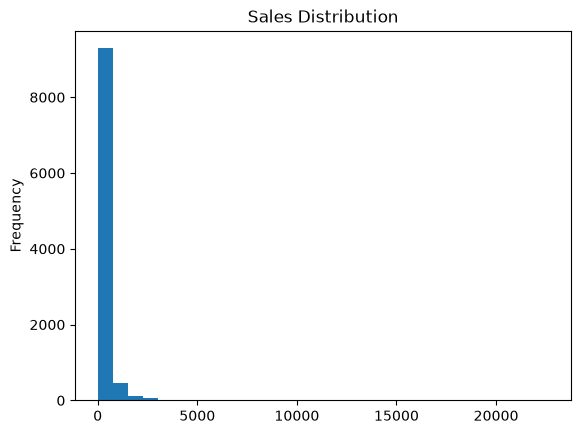

In [178]:
df["Sales"].plot(kind="hist", bins=30, title="Sales Distribution")

**224.** Create a histogram showing the distribution of Profit.

<Axes: title={'center': 'Profit Distribution'}, ylabel='Frequency'>

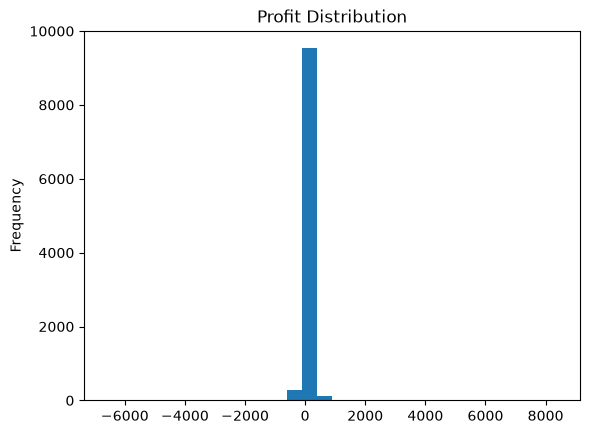

In [179]:
df["Profit"].plot(kind="hist", bins=30, title="Profit Distribution")

**225.** Create a box plot showing sales distribution across categories.

<Axes: title={'center': 'Sales'}, xlabel='Category'>

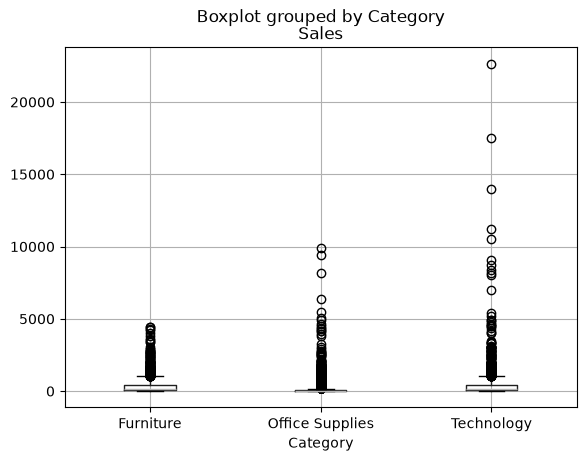

In [180]:
df.boxplot(column="Sales", by="Category")

**226.** Create a box plot showing profit distribution across regions.

**227.** Create a stacked bar chart showing category-wise sales by region.

**228.** Create a count plot showing the number of orders by shipping mode.

**229.** Create a treemap showing category and sub-category sales distribution.

**230.** Create a correlation heatmap for numerical columns.

## Section 13 – Advanced Business Intelligence and Analytical Questions

**231.** Which products generate the highest revenue but contribute very little to overall profit?

In [181]:
product_data = df.groupby("Product Name")[["Sales", "Profit"]].sum()
print(product_data.sort_values("Sales", ascending=False).head(10))

                                                        Sales        Profit
Product Name                                                               
Canon imageCLASS 2200 Advanced Copier               61599.824  2.519993e+04
Fellowes PB500 Electric Punch Plastic Comb Bind...  27453.384  7.753039e+03
Cisco TelePresence System EX90 Videoconferencin...  22638.480 -1.811078e+03
HON 5400 Series Task Chairs for Big and Tall        21870.576  5.684342e-14
GBC DocuBind TL300 Electric Binding System          19823.479  2.233505e+03
GBC Ibimaster 500 Manual ProClick Binding System    19024.500  7.609800e+02
Hewlett Packard LaserJet 3310 Copier                18839.686  6.983884e+03
HP Designjet T520 Inkjet Large Format Printer -...  18374.895  4.094977e+03
GBC DocuBind P400 Electric Binding System           17965.068 -1.878166e+03
High Speed Automatic Electric Letter Opener         17030.312 -2.620048e+02


**232.** Which products should the company consider discontinuing based on consistent losses?

In [182]:
product_profit = df.groupby("Product Name")["Profit"].sum()
print(product_profit[product_profit < 0].sort_values().head(10))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


**233.** Which categories have the highest sales growth?

In [183]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df.groupby(["Category", df["Order Date"].dt.year])["Sales"].sum())

Category         Order Date
Furniture        2014          157192.8531
                 2015          170518.2370
                 2016          198901.4360
                 2017          215387.2692
Office Supplies  2014          151776.4120
                 2015          137233.4630
                 2016          183939.9820
                 2017          246097.1750
Technology       2014          175278.2330
                 2015          162780.8090
                 2016          226364.1800
                 2017          271730.8110
Name: Sales, dtype: float64


**234.** Which categories have the highest profit margins?

In [184]:
category_data = df.groupby("Category")[["Sales", "Profit"]].sum()
print((category_data["Profit"] / category_data["Sales"] * 100).sort_values(ascending=False))

Category
Technology         17.395712
Office Supplies    17.035158
Furniture           2.486695
dtype: float64


**235.** Does a higher sales volume necessarily result in higher profit?

In [185]:
print(df[["Sales", "Profit"]].corr())

           Sales    Profit
Sales   1.000000  0.479064
Profit  0.479064  1.000000


**236.** Are high-discount products more likely to generate losses?

In [186]:
print(df.groupby("Discount")["Profit"].mean())

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


**237.** Which customer segment generates the highest revenue per order?

In [187]:
segment_data = df.groupby("Segment").agg({"Sales": "sum", "Order ID": "nunique"})
print(segment_data["Sales"] / segment_data["Order ID"])

Segment
Consumer       449.111116
Corporate      466.411075
Home Office    472.665730
dtype: float64


**238.** Which region has the best balance between sales and profitability?

In [188]:
region_data = df.groupby("Region")[["Sales", "Profit"]].sum()
region_data["Profit Margin"] = region_data["Profit"] / region_data["Sales"] * 100
print(region_data)

               Sales       Profit  Profit Margin
Region                                          
Central  501239.8908   39706.3625       7.921629
East     678781.2400   91522.7800      13.483399
South    391721.9050   46749.4303      11.934342
West     725457.8245  108418.4489      14.944831


**239.** Which products are popular but financially unattractive?

In [189]:
product_data = df.groupby("Product Name")[["Sales", "Profit"]].sum()
print(product_data[(product_data["Sales"] > product_data["Sales"].median()) & (product_data["Profit"] < 0)])

                                                       Sales    Profit
Product Name                                                          
3.6 Cubic Foot Counter Height Office Refrigerator   2946.200 -872.0752
36X48 HARDFLOOR CHAIRMAT                             369.248  -40.4914
3D Systems Cube Printer, 2nd Generation, White      2339.982 -467.9964
Acco Smartsocket Color-Coded Six-Outlet AC Adap...   448.902   -7.0416
Anker Astro 15000mAh USB Portable Charger            599.880  -23.9952
...                                                      ...       ...
V7 USB Numeric Keypad                                461.868  -58.7832
Wilson Jones Elliptical Ring 3 1/2" Capacity Bi...   834.600  -82.1760
Xerox WorkCentre 6505DN Laser Multifunction Pri...  2519.958 -251.9958
Zebra GK420t Direct Thermal/Thermal Transfer Pr...   703.710 -938.2800
i.Sound Portable Power - 8000 mAh                    413.322  -58.8189

[198 rows x 2 columns]


**240.** Which customers contribute most to total company profit?

In [190]:
print(df.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False).head(10))

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


**241.** What percentage of total profit is generated by the top 20% of customers?

In [191]:
customer_profit = df.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False)
top_count = int(len(customer_profit) * 0.2)
print(customer_profit.head(top_count).sum() / df["Profit"].sum() * 100)

81.42587496747005


**242.** What percentage of total sales is generated by the top 20% of products?

In [192]:
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)
top_count = int(len(product_sales) * 0.2)
print(product_sales.head(top_count).sum() / df["Sales"].sum() * 100)

76.83932023991503


**243.** Identify the most profitable combination of Region, Category and Segment.

In [193]:
print(df.groupby(["Region", "Category", "Segment"])["Profit"].sum().sort_values(ascending=False).head(10))

Region   Category         Segment    
West     Technology       Consumer       27785.5681
         Office Supplies  Consumer       25334.3679
East     Technology       Consumer       19930.1794
         Office Supplies  Consumer       19222.6927
West     Office Supplies  Corporate      18527.7008
East     Technology       Home Office    17709.0675
Central  Technology       Corporate      16282.6133
East     Office Supplies  Corporate      13457.6650
South    Technology       Consumer       13106.7230
West     Technology       Corporate      11941.0632
Name: Profit, dtype: float64


**244.** Identify the least profitable combination of Region, Category and Segment.

In [194]:
print(df.groupby(["Region", "Category", "Segment"])["Profit"].sum().sort_values().head(10))

Region   Category         Segment    
Central  Furniture        Consumer      -3994.4342
                          Home Office   -1198.6091
         Office Supplies  Corporate        99.2948
East     Furniture        Corporate       342.1257
                          Home Office     665.9279
South    Technology       Home Office     764.5751
         Furniture        Corporate       952.0303
                          Home Office    1202.4432
East     Furniture        Consumer       2038.1122
Central  Furniture        Corporate      2321.9939
Name: Profit, dtype: float64


**245.** Which shipping mode generates the highest profit per order?

In [195]:
order_profit = df.groupby(["Ship Mode", "Order ID"])["Profit"].sum().reset_index()
print(order_profit.groupby("Ship Mode")["Profit"].mean().sort_values(ascending=False))

Ship Mode
First Class       62.223431
Same Day          60.196056
Second Class      59.591945
Standard Class    54.805874
Name: Profit, dtype: float64


**246.** Are there specific months where the business consistently experiences losses?

**247.** Identify products that perform well in one region but poorly in another.

**248.** Identify customer segments that prefer particular product categories.

**249.** Determine whether discount policies should vary by product category.

**250.** Based on the complete analysis, recommend five strategies to improve business profitability.

## Section 14 – Critical Thinking and Case Studies

**251.** The company has high sales but relatively low profit. Investigate possible reasons using the dataset.

In [196]:
print("Total sales:", df["Sales"].sum())
print("Total profit:", df["Profit"].sum())
print("Overall profit margin:", df["Profit"].sum() / df["Sales"].sum() * 100)
print("Average discount:", df["Discount"].mean())
print("Profit by category:")
print(df.groupby("Category")["Profit"].sum())
print("Profit by discount:")
print(df.groupby("Discount")["Profit"].sum())
print("Loss-making transactions:", (df["Profit"] < 0).sum())

Total sales: 2297200.8603
Total profit: 286397.0217
Overall profit margin: 12.467217240315605
Average discount: 0.1562027216329798
Profit by category:
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64
Profit by discount:
Discount
0.00    320987.6032
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64
Loss-making transactions: 1871


**252.** Furniture has high sales. Determine whether it is also the most profitable category.

In [197]:
print(df.groupby("Category")[["Sales", "Profit"]].sum())

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


**253.** A product has generated $50,000 in sales but only $500 in profit. Explain its business performance.

In [198]:
profit_margin = 500 / 50000 * 100
print("Profit margin:", profit_margin, "%")

Profit margin: 1.0 %


**254.** A product has generated $10,000 in sales and $3,000 in profit. Compare its profitability with the previous product.

In [199]:
first_margin = 500 / 50000 * 100
second_margin = 3000 / 10000 * 100
print("First product margin:", first_margin, "%")
print("Second product margin:", second_margin, "%")

First product margin: 1.0 %
Second product margin: 30.0 %


**255.** Identify five products that should receive more marketing investment.

In [200]:
print(df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(5))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Name: Profit, dtype: float64


**256.** Identify five products for which discounts should be reduced.

In [201]:
print(df.groupby("Product Name")["Profit"].sum().sort_values().head(5))

Product Name
Cubify CubeX 3D Printer Double Head Print                  -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                  -4589.9730
Cubify CubeX 3D Printer Triple Head Print                  -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases   -2876.1156
Bush Advantage Collection Racetrack Conference Table       -1934.3976
Name: Profit, dtype: float64


**257.** Identify five customers who should be considered high-value customers.

In [202]:
customer_data = df.groupby("Customer Name")[["Sales", "Profit"]].sum()
print(customer_data.sort_values("Profit", ascending=False).head(5))

                   Sales     Profit
Customer Name                      
Tamara Chand   19052.218  8981.3239
Raymond Buch   15117.339  6976.0959
Sanjit Chand   14142.334  5757.4119
Hunter Lopez   12873.298  5622.4292
Adrian Barton  14473.571  5444.8055


**258.** Identify geographical areas where the company should expand its business.

In [203]:
print(df.groupby("State")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False).head(10))

                    Sales      Profit
State                                
California    457687.6315  76381.3871
New York      310876.2710  74038.5486
Texas         170188.0458 -25729.3563
Washington    138641.2700  33402.6517
Pennsylvania  116511.9140 -15559.9603
Florida        89473.7080  -3399.3017
Illinois       80166.1010 -12607.8870
Ohio           78258.1360 -16971.3766
Michigan       76269.6140  24463.1876
Virginia       70636.7200  18597.9504


**259.** Determine whether the company's sales growth is accompanied by profit growth.

In [204]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df.groupby(df["Order Date"].dt.year)[["Sales", "Profit"]].sum())

                  Sales      Profit
Order Date                         
2014        484247.4981  49543.9741
2015        470532.5090  61618.6037
2016        609205.5980  81795.1743
2017        733215.2552  93439.2696


**260.** Develop a strategy to increase sales without significantly reducing profit margins.

In [205]:
print("Category-wise sales and profit:")
print(df.groupby("Category")[["Sales", "Profit"]].sum())
print("Profit by discount:")
print(df.groupby("Discount")["Profit"].mean())
print("Suggested strategies:")
print("1. Review high-discount transactions that produce losses.")
print("2. Promote products with strong sales and positive profit.")
print("3. Reduce discounts on products with weak profit margins.")
print("4. Focus marketing on profitable customer segments and regions.")
print("5. Monitor sales and profit together before expanding a product.")

Category-wise sales and profit:
                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481
Profit by discount:
Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64
Suggested strategies:
1. Review high-discount transactions that produce losses.
2. Promote products with strong sales and positive profit.
3. Reduce discounts on products with weak profit margins.
4. Focus marketing on profitable customer segments and regions.
5. Monitor sales and profit together before expanding a product.


## Section 15 – Mini Projects

Complete one or more of the following projects. Each project should include data preparation, analysis, visualizations, findings and recommendations.

### 1. Sales Performance Dashboard

Build a dashboard showing total sales, profit, orders, customers and category performance.

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009
Total Customers: 793


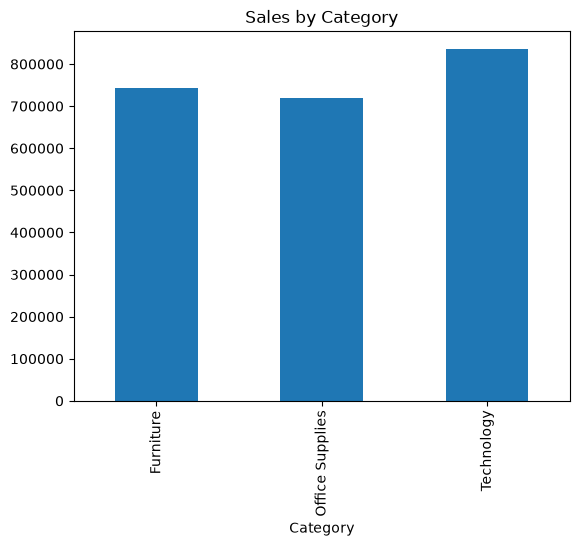

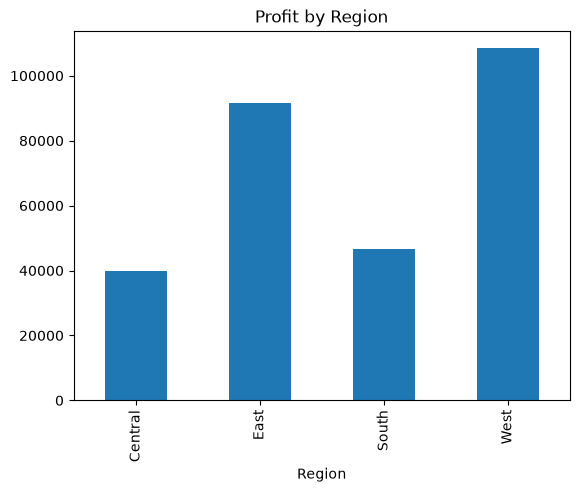

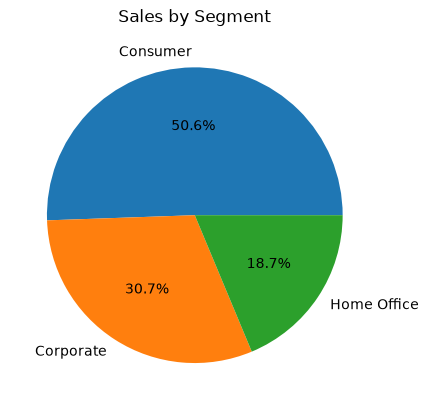

In [206]:
import matplotlib.pyplot as plt

print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Orders:", df["Order ID"].nunique())
print("Total Customers:", df["Customer ID"].nunique())

df.groupby("Category")["Sales"].sum().plot(kind="bar", title="Sales by Category")
plt.show()
df.groupby("Region")["Profit"].sum().plot(kind="bar", title="Profit by Region")
plt.show()
df.groupby("Segment")["Sales"].sum().plot(kind="pie", autopct="%1.1f%%", title="Sales by Segment")
plt.show()

### 2. Product Profitability Report

Identify the most and least profitable products and categories.

Top profitable products:
                                                                        Sales  \
Product Name                                       Category                     
Canon imageCLASS 2200 Advanced Copier              Technology       61599.824   
Fellowes PB500 Electric Punch Plastic Comb Bind... Office Supplies  27453.384   
Hewlett Packard LaserJet 3310 Copier               Technology       18839.686   
Canon PC1060 Personal Laser Copier                 Technology       11619.834   
HP Designjet T520 Inkjet Large Format Printer -... Technology       18374.895   
Ativa V4110MDD Micro-Cut Shredder                  Technology        7699.890   
3D Systems Cube Printer, 2nd Generation, Magenta   Technology       14299.890   
Plantronics Savi W720 Multi-Device Wireless Hea... Technology        9367.290   
Ibico EPK-21 Electric Binding System               Office Supplies  15875.916   
Zebra ZM400 Thermal Label Printer                  Technology        6965.700   

  

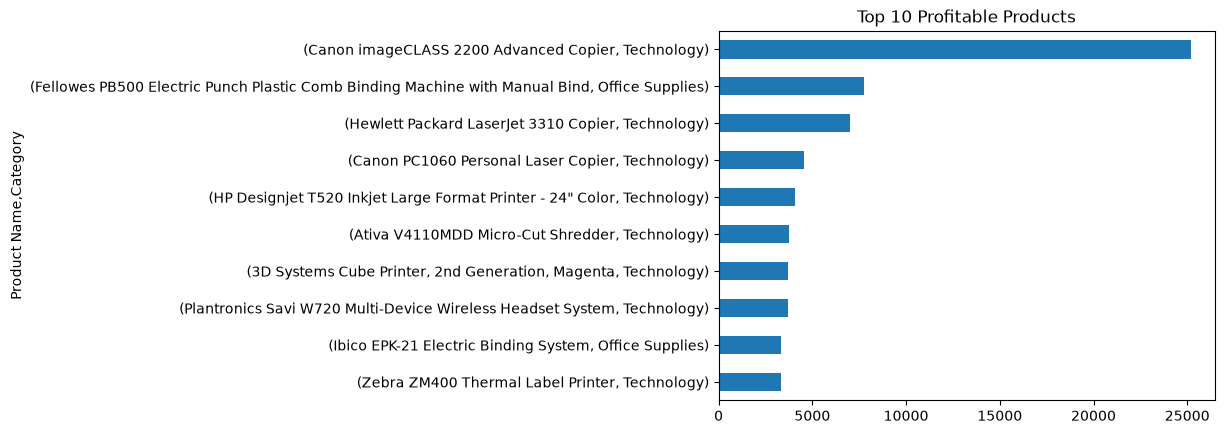

In [207]:
product_report = df.groupby(["Product Name", "Category"])[["Sales", "Profit", "Quantity"]].sum()
print("Top profitable products:")
print(product_report.sort_values("Profit", ascending=False).head(10))
print("Least profitable products:")
print(product_report.sort_values("Profit").head(10))
print("Category profitability:")
print(df.groupby("Category")[["Sales", "Profit"]].sum())
product_report["Profit"].nlargest(10).sort_values().plot(kind="barh", title="Top 10 Profitable Products")
plt.show()

### 3. Customer Analysis

Identify high-value customers and segment customers based on purchasing behavior.

High-value customers:
                          Sales     Profit  Orders
Customer Name                                     
Tamara Chand          19052.218  8981.3239       5
Raymond Buch          15117.339  6976.0959       6
Sanjit Chand          14142.334  5757.4119       9
Hunter Lopez          12873.298  5622.4292       6
Adrian Barton         14473.571  5444.8055      10
Tom Ashbrook          14595.620  4703.7883       4
Christopher Martinez   8954.020  3899.8904       4
Keith Dawkins          8181.256  3038.6254      12
Andy Reiter            6608.448  2884.6208       6
Daniel Raglin          8350.868  2869.0760       8
Customers with losses:
                      Sales    Profit  Orders
Customer Name                                
Aaron Smayling    3050.6920 -253.5746       7
Adrian Hane       1735.5140   -2.3146       7
Alan Haines       1587.4520 -378.5509       4
Alex Avila        5563.5600 -362.8825       5
Alex Grayson       660.9720   -5.1371       5
Alex Russell      105

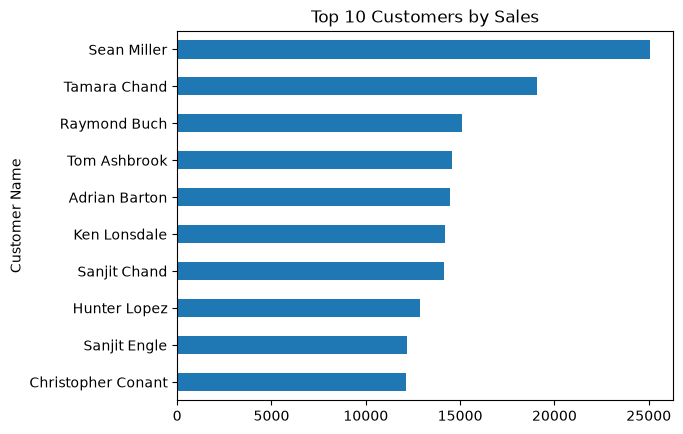

In [208]:
customer_report = df.groupby("Customer Name").agg({"Sales": "sum", "Profit": "sum", "Order ID": "nunique"})
customer_report = customer_report.rename(columns={"Order ID": "Orders"})
print("High-value customers:")
print(customer_report.sort_values("Profit", ascending=False).head(10))
print("Customers with losses:")
print(customer_report[customer_report["Profit"] < 0].head(10))
customer_report["Sales"].nlargest(10).sort_values().plot(kind="barh", title="Top 10 Customers by Sales")
plt.show()

### 4. Regional Sales Analysis

Compare sales and profit across regions, states and cities.

               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489
Top states by sales:
                    Sales      Profit
State                                
California    457687.6315  76381.3871
New York      310876.2710  74038.5486
Texas         170188.0458 -25729.3563
Washington    138641.2700  33402.6517
Pennsylvania  116511.9140 -15559.9603
Florida        89473.7080  -3399.3017
Illinois       80166.1010 -12607.8870
Ohio           78258.1360 -16971.3766
Michigan       76269.6140  24463.1876
Virginia       70636.7200  18597.9504
Top cities by profit:
                    Sales      Profit
City                                 
New York City  256368.161  62036.9837
Los Angeles    175851.341  30440.7579
Seattle        119540.742  29156.0967
San Francisco  112669.092  17507.3854
Detroit         42446.944  13181.7908
Lafayette       25036.200  1001

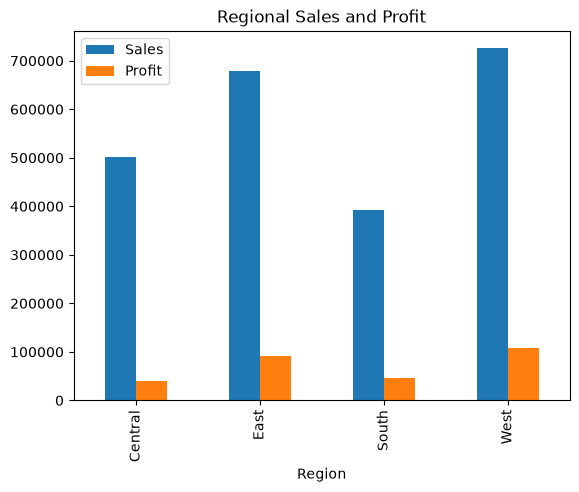

In [209]:
region_report = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region_report)
state_report = df.groupby("State")[["Sales", "Profit"]].sum()
print("Top states by sales:")
print(state_report.sort_values("Sales", ascending=False).head(10))
city_report = df.groupby("City")[["Sales", "Profit"]].sum()
print("Top cities by profit:")
print(city_report.sort_values("Profit", ascending=False).head(10))
region_report.plot(kind="bar", title="Regional Sales and Profit")
plt.show()

### 5. Discount Optimization

Analyze discount patterns and recommend an appropriate discount strategy.

Average discount: 0.1562027216329798
Profit by discount:
Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64


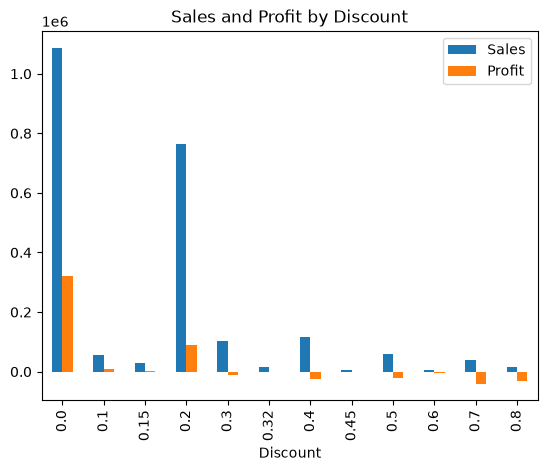

Discount levels with negative total profit:
                Sales      Profit
Discount                         
0.30      103226.6550 -10369.2774
0.32       14493.4588  -2391.1377
0.40      116417.7840 -23057.0504
0.45        5484.9740  -2493.1111
0.50       58918.5400 -20506.4281
0.60        6644.7000  -5944.6552
0.70       40620.2820 -40075.3569
0.80       16963.7560 -30539.0392


In [210]:
print("Average discount:", df["Discount"].mean())
print("Profit by discount:")
print(df.groupby("Discount")["Profit"].mean())
discount_report = df.groupby("Discount")[["Sales", "Profit"]].sum()
discount_report.plot(kind="bar", title="Sales and Profit by Discount")
plt.show()
print("Discount levels with negative total profit:")
print(discount_report[discount_report["Profit"] < 0])

### 6. Time-Series Analysis

Analyze monthly and yearly sales trends and identify seasonal patterns.

                  Sales      Profit
Order Date                         
2014-01      14236.8950   2450.1907
2014-02       4519.8920    862.3084
2014-03      55691.0090    498.7299
2014-04      28295.3450   3488.8352
2014-05      23648.2870   2738.7096
2014-06      34595.1276   4976.5244
2014-07      33946.3930   -841.4826
2014-08      27909.4685   5318.1050
2014-09      81777.3508   8328.0994
2014-10      31453.3930   3448.2573
2014-11      78628.7167   9292.1269
2014-12      69545.6205   8983.5699
2015-01      18174.0756  -3281.0070
2015-02      11951.4110   2813.8508
2015-03      38726.2520   9732.0978
2015-04      34195.2085   4187.4962
2015-05      30131.6865   4667.8690
2015-06      24797.2920   3335.5572
2015-07      28765.3250   3288.6483
2015-08      36898.3322   5355.8084
2015-09      64595.9180   8209.1627
2015-10      31404.9235   2817.3660
2015-11      75972.5635  12474.7884
2015-12      74919.5212   8016.9659
2016-01      18542.4910   2824.8233
2016-02      22978.8150   50

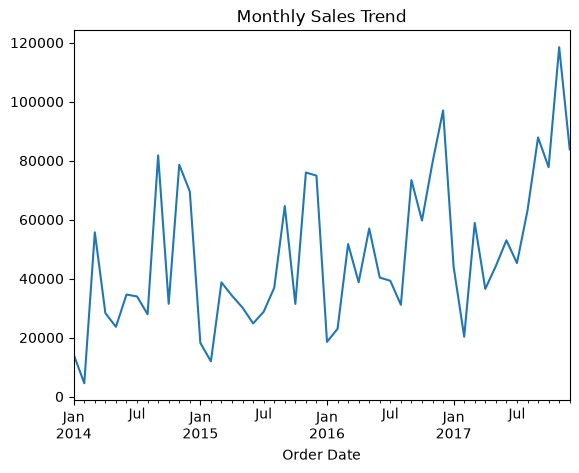

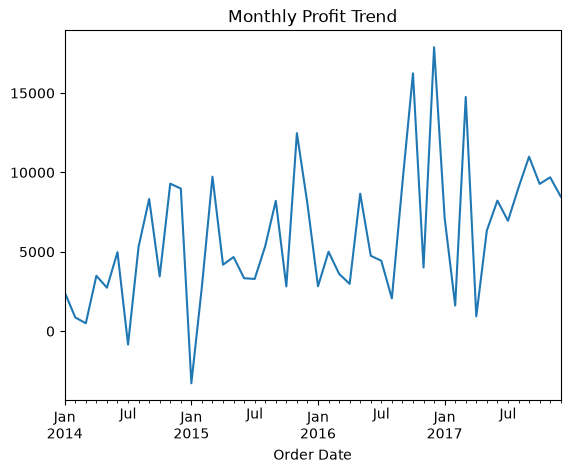

Yearly performance:
                  Sales      Profit
Order Date                         
2014        484247.4981  49543.9741
2015        470532.5090  61618.6037
2016        609205.5980  81795.1743
2017        733215.2552  93439.2696


In [211]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
monthly_report = df.groupby(df["Order Date"].dt.to_period("M"))[["Sales", "Profit"]].sum()
print(monthly_report)
monthly_report["Sales"].plot(kind="line", title="Monthly Sales Trend")
plt.show()
monthly_report["Profit"].plot(kind="line", title="Monthly Profit Trend")
plt.show()
print("Yearly performance:")
print(df.groupby(df["Order Date"].dt.year)[["Sales", "Profit"]].sum())

### 7. Business Performance Report

Prepare a complete business performance report with visualizations and recommendations.

Category performance:
                       Sales       Profit  Profit Margin
Category                                                
Furniture        741999.7953   18451.2728       2.486695
Office Supplies  719047.0320  122490.8008      17.035158
Technology       836154.0330  145454.9481      17.395712
15 analytical findings:
1. Total sales: 2297200.8603
2. Total profit: 286397.0217
3. Overall profit margin: 12.467217240315605
4. Total orders: 5009
5. Total customers: 793
6. Highest sales category: Technology
7. Highest profit category: Technology
8. Lowest profit category: Furniture
9. Highest sales region: West
10. Highest profit region: West
11. Most profitable segment: Consumer
12. Most used shipping mode: Standard Class
13. Average discount: 0.1562027216329798
14. Number of loss-making rows: 1871
15. Number of unique products: 1862
Business recommendations:
1. Review discounts on loss-making products.
2. Promote products with consistently high profit.
3. Study low-profit catego

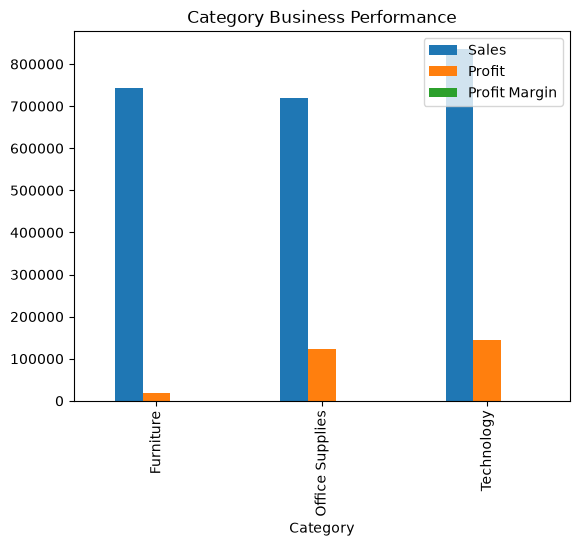

In [212]:
business_report = df.groupby("Category")[["Sales", "Profit"]].sum()
business_report["Profit Margin"] = business_report["Profit"] / business_report["Sales"] * 100
print("Category performance:")
print(business_report)
print("15 analytical findings:")
print("1. Total sales:", df["Sales"].sum())
print("2. Total profit:", df["Profit"].sum())
print("3. Overall profit margin:", df["Profit"].sum() / df["Sales"].sum() * 100)
print("4. Total orders:", df["Order ID"].nunique())
print("5. Total customers:", df["Customer ID"].nunique())
print("6. Highest sales category:", df.groupby("Category")["Sales"].sum().idxmax())
print("7. Highest profit category:", df.groupby("Category")["Profit"].sum().idxmax())
print("8. Lowest profit category:", df.groupby("Category")["Profit"].sum().idxmin())
print("9. Highest sales region:", df.groupby("Region")["Sales"].sum().idxmax())
print("10. Highest profit region:", df.groupby("Region")["Profit"].sum().idxmax())
print("11. Most profitable segment:", df.groupby("Segment")["Profit"].sum().idxmax())
print("12. Most used shipping mode:", df["Ship Mode"].value_counts().idxmax())
print("13. Average discount:", df["Discount"].mean())
print("14. Number of loss-making rows:", (df["Profit"] < 0).sum())
print("15. Number of unique products:", df["Product ID"].nunique())
print("Business recommendations:")
print("1. Review discounts on loss-making products.")
print("2. Promote products with consistently high profit.")
print("3. Study low-profit categories and sub-categories.")
print("4. Focus marketing on profitable customer segments.")
print("5. Monitor regional sales and profit together.")
business_report.plot(kind="bar", title="Category Business Performance")
plt.show()

### 8. Executive Sales Dashboard

Develop an interactive dashboard using Streamlit or Power BI.

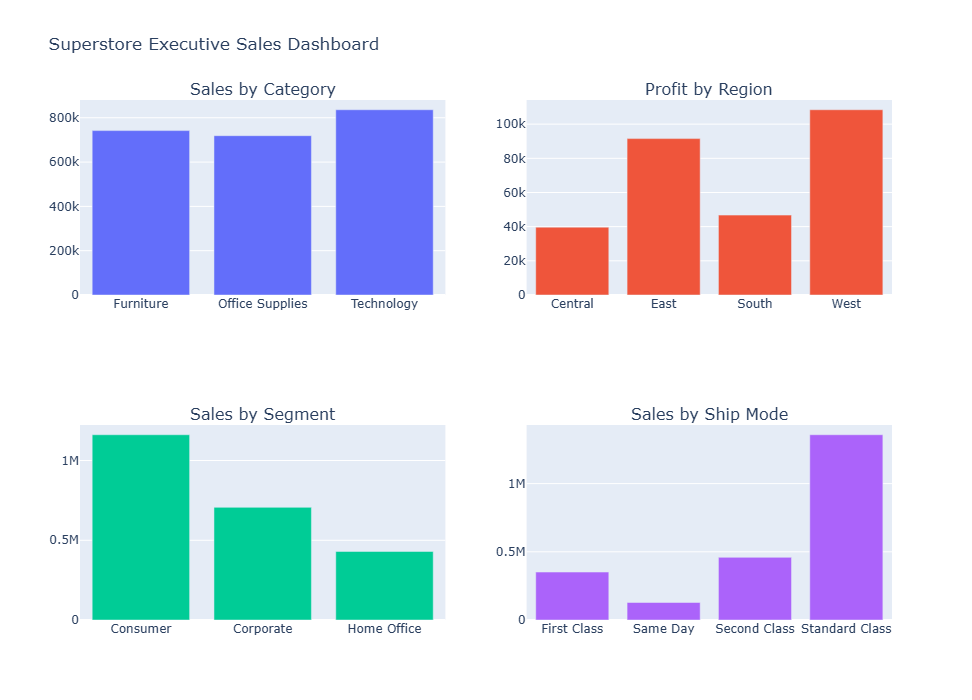

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009
Total Customers: 793


In [214]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

category_sales = df.groupby("Category")["Sales"].sum()
region_profit = df.groupby("Region")["Profit"].sum()
segment_sales = df.groupby("Segment")["Sales"].sum()
ship_sales = df.groupby("Ship Mode")["Sales"].sum()

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=("Sales by Category", "Profit by Region",
                    "Sales by Segment", "Sales by Ship Mode")
)
fig.add_trace(go.Bar(x=category_sales.index, y=category_sales.values), row=1, col=1)
fig.add_trace(go.Bar(x=region_profit.index, y=region_profit.values), row=1, col=2)
fig.add_trace(go.Bar(x=segment_sales.index, y=segment_sales.values), row=2, col=1)
fig.add_trace(go.Bar(x=ship_sales.index, y=ship_sales.values), row=2, col=2)
fig.update_layout(
    title_text="Superstore Executive Sales Dashboard",
    showlegend=False,
    height=700
)
fig.show()
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Orders:", df["Order ID"].nunique())
print("Total Customers:", df["Customer ID"].nunique())

## Recommended Assignment Submission Requirements

**1.** Python source code or Jupyter Notebook.

**2.** Data cleaning and preprocessing steps.

**3.** Pandas operations used for analysis.

**4.** At least 10 meaningful visualizations.

**5.** At least 15 analytical findings.

**6.** Five business recommendations based on the findings.

**7.** A final conclusion explaining the overall business performance.

## Suggested Assessment Distribution

| Assessment component | Marks |
|---|---:|
| Data understanding and cleaning | 10 |
| Sales analysis | 15 |
| Profitability analysis | 15 |
| Product and category analysis | 15 |
| Customer and regional analysis | 10 |
| Discount and time-series analysis | 10 |
| Data visualization | 10 |
| Business insights and recommendations | 10 |
| Code quality and presentation | 5 |
| **Total** | **100** |

## Instructor's Suggested Use

Make Sections 1–5 compulsory. Select questions from Sections 6–12 for practical exercises. Use Sections 13–15 for individual or group projects. This structure assesses both Pandas programming skills and students' ability to interpret data and make business recommendations.
